# Лабораторная работа № 1. Парсинг динамических веб-сайтов с Playwright в Google Colab

**Направление:** 38.04.05 «Бизнес-информатика» (магистратура)  
**Среда:** Google Colab · headless Chromium · **максимум 10 баллов**

## Цель

Освоить автоматизированный сбор данных со страниц, содержимое которых формируется JavaScript, обработку динамической загрузки и подготовку аналитических выводов по собранным данным.

## Что необходимо выполнить

1. Показать различие между исходным HTML и страницей после выполнения JavaScript.
2. Запустить Chromium в Google Colab, выполнить основной сценарий на **Playwright**. Selenium рассматривается как альтернативный инструмент в теоретической части; программный шаблон шагов 2–7 реализован для Playwright.
3. Обработать cookie-баннер, дождаться появления строк, загрузить все данные и извлечь их через XPath и `lxml`.
4. Очистить числа с суффиксами K/M/B, проценты, валюты, даты и пропуски; проверить функции тестами и сформировать Excel.
5. Построить **четыре содержательных графика**, рассчитать доступные показатели и сформулировать **три наблюдения с числами и 2–3 практические рекомендации**.
6. Кратко охарактеризовать указанную в варианте реальную площадку, ограничения автоматизированного доступа и возможный легальный источник данных **без обязательного парсинга реального сайта**.

**Результат:** выполненный `.ipynb` с сохранёнными выводами ячеек, Excel и скриншот учебного стенда после загрузки данных. Файлы размещаются в личном публичном репозитории GitHub; в LMS сдаётся ссылка на репозиторий.


## Выполнение: вариант 2 — «Фондовые индексы АТР» (профиль стенда `stocks`)

**Выполнил(а):** _ФИО, группа_

| Параметр | Значение |
|---|---|
| Движок | Playwright (async API), headless Chromium |
| Профиль стенда / вариант | `stocks` / `VARIANT = 2` |
| Реальная площадка (разбор ограничений) | Investing.com — Asia/Pacific indices |
| Легальные источники | MOEX ISS API, Alpha Vantage |
| Аналитическая задача | сравнение доходностей, когорты роста и падения → ребалансировка регионального портфеля |
| Задание со звёздочкой | направление **D** — устойчивость к смене вёрстки (каскад селекторов + 8 тестов поломки разметки) |
| Артефакты в `WORK_DIR` | `page.png`, `lr1_variant02_stocks.xlsx`, `charts/01–04_*.png`, `robustness_tests/`, `star_d/`, `market_stand.html` |

Реализованы все `TODO` (2.1, 3.1, 4.1, 5.1–5.3, 6.1–6.5, 7.1–7.2). Дополнительно добавлен шаг 5.4: проверка требований к отказоустойчивости на копиях стенда со сломанной вёрсткой. Задание со звёздочкой (направление D) выполнено в конце ноутбука. Решения по шагам и выводы — в markdown-ячейках после соответствующих шагов и в разделе «Заключение» перед таблицей вариантов.

## Как выполнять лабораторную работу

### 1. Обязательная часть — учебный стенд

Ноутбук самостоятельно запускает локальный учебный стенд `Market Monitor`: HTML-каркас загружается до данных, строки появляются после выполнения JavaScript, действует cookie-баннер, последующие записи подгружаются кнопкой «Показать ещё». Для каждого варианта установлены свой профиль и воспроизводимые учебные значения.

- Укажите выданный номер в параметре `VARIANT` (**1–30**).
- Оставьте `ENGINE = "playwright"` и `USE_LIVE_TARGET = False`. Хотя Selenium рассматривается в теоретической части, дальнейшие кодовые заготовки используют асинхронный API Playwright.
- Выполните ячейки **по порядку**, самостоятельно дописывая отмеченные `TODO`. Вызов `todo("…")` специально вызывает `NotImplementedError`, пока соответствующее задание не реализовано.
- Через браузер обработайте баннер, дождитесь отображения строк, выполните догрузку и получите **все 30 уникальных позиций**. Используйте явные ожидания, а не `time.sleep()`.
- Проверьте функции очистки, получите обработанную таблицу, сохраните Excel, **четыре графика**, аналитические выводы и скриншот загруженного стенда `page.png` в `WORK_DIR`. Скриншот нужен и при успешном выполнении, а не только при ошибке.

### 2. Реальная площадка — исследование, а не второй парсер

Столбцы «Реальная площадка» и «Легальный источник» в таблице вариантов нужны **для краткого текстового анализа**, который включается в заключение. Укажите назначение площадки, сведения об ограничениях (доступные `robots.txt` и пользовательское соглашение), наличие публично доступных XHR/fetch или API **если это удалось установить**, а также возможный разрешённый способ получения аналогичных данных. Если определить XHR/API или ознакомиться с правилами не удалось, прямо обозначьте ограничение — **никакого обязательного автоматического сбора с реального сайта нет**.

Селекторы cookie-баннеров внешних сайтов, смена `USE_LIVE_TARGET` на `True` и интеграция с указанным API **для обязательной части не требуются**. Не обходите CAPTCHA/Cloudflare и другие ограничения доступа, не собирайте данные из закрытых разделов и персональные данные.

### 3. Аналитика по индивидуальному варианту

Профили стенда (`crypto`, `stocks`, `metals`, `ecom`, `startups`) имеют одинаковую структуру полей: идентификатор, наименование, категория, цена, изменение, условные показатели `volume`/`mcap` и дата. **Некоторых предметных показателей из формулировки бизнес-задачи в стенде нет** (например, остатков товара, биржевых спредов, стадии инвестиционного раунда, вакансий и реальных продаж).

Рассчитывайте только показатели, для которых есть исходные поля. Недоступную метрику **не придумывайте и не подменяйте** показателем с другим смыслом. Вместо неё используйте доступные показатели для четырёх содержательных графиков и объясните, какие данные потребовались бы для исходной бизнес-задачи. Например, для варианта 24 нельзя вычислить долю отсутствующих SKU без остатков; допустим анализ цен, категорий и полноты карточек с указанием этого ограничения.

### 4. Самопроверка и сдача

Запустите встроенную самопроверку, устраните замечания к действительно выполненным этапам и приложите все результаты. **Самопроверка носит вспомогательный характер**: в исходной ячейке проверка `COLLECT_SOURCE` не получает значение автоматически, а проверка графиков зависит от их состояния на момент запуска. Поэтому отметка «❌» по этим пунктам сама по себе не подтверждает ошибку — преподаватель оценивает код, выводы и сохранённые артефакты. Не редактируйте проверки ради формального получения всех галочек.

**Для Google Colab:** допускается `await` в ячейках; при использовании Playwright нужен его асинхронный API. Установка браузера может понадобиться заново после сброса среды.


## Теоретический блок 1. Почему статический парсинг бессилен

### Два способа доставить страницу пользователю

| | Server-Side Rendering | Client-Side Rendering (SPA) |
|---|---|---|
| Что приходит в ответ на GET | готовый HTML с данными | «скелет»: пустой `<div id="root">` и ссылки на бандлы |
| Где берутся данные | сервер собрал их до отправки | браузер выполняет JS, тот запрашивает JSON и строит DOM |
| Что увидит `requests` | данные | пустой каркас |
| Типичный стек | Django, Rails, классический PHP | React, Angular, Vue, Svelte |

**Гидратация** — момент, когда загруженный JavaScript «оживляет» разметку и подставляет данные. До неё в DOM нужных узлов физически нет. В нашем стенде это видно буквально: в исходном HTML ноль строк таблицы, а после гидратации их двенадцать.

### Как отличить одно от другого за 15 секунд

1. `view-source:` или `requests.get(url).text` — есть ли в ответе искомое число?
2. Если нет — открыть DevTools → вкладка **Network** → фильтр **Fetch/XHR** и перезагрузить страницу. Часто данные приходят одним JSON-запросом: тогда браузер не нужен вовсе, достаточно обратиться к этому эндпоинту (это самый быстрый и устойчивый путь).
3. Если данные собираются множеством запросов, приходят в зашифрованном виде или защищены проверкой браузера — нужен headless-браузер.

### Что ещё ломает наивный сбор

* **Отложенная подгрузка**: бесконечная прокрутка, кнопки «Показать ещё», ленивые изображения.
* **Оверлеи**: cookie-баннеры, модальные окна о регионе и подписке — они перекрывают клики.
* **Проверки браузера**: Cloudflare и подобные системы выполняют JS-challenge и проверяют отпечаток клиента. Их обход — не учебная задача: если площадка явно не хочет автоматических обращений, аналитик ищет официальный API или лицензированного поставщика данных.
* **Разметка без смысловых якорей**: сгенерированные классы вида `css-1x7ab3e`. Опора на такие классы — гарантированная поломка после следующего релиза.

### Экономика вопроса

Браузер дороже HTTP-запроса в десятки раз: запуск процесса, рендеринг, исполнение JS. Поэтому порядок выбора инструмента такой: **официальный API → скрытый JSON-эндпоинт → HTML без JS → headless-браузер**. Браузер — последний рубеж, а не первый.

## Теоретический блок 2. Selenium против Playwright

| Критерий | Selenium 4.x | Playwright 1.x |
|---|---|---|
| Протокол | W3C WebDriver: скрипт → драйвер → браузер | CDP (Chrome DevTools Protocol) напрямую, один WebSocket |
| Установка браузера | Chrome ставится отдельно, драйвер подбирает Selenium Manager | `playwright install chromium` кладёт совместимую сборку |
| Ожидания | неявные (`implicitly_wait`) и явные (`WebDriverWait` + `expected_conditions`) | автоожидание в каждом действии + явные `wait_for_selector` / `wait_for_function` |
| Асинхронность | синхронный API (есть сторонние обёртки) | синхронный и асинхронный API; в Jupyter обязателен асинхронный |
| Изоляция | новый профиль или новый браузер | `browser_context` — «инкогнито» за миллисекунды, десятки контекстов на один браузер |
| Сеть | перехват ограничен | `page.route()`: блокировка картинок, подмена ответов, чтение XHR |
| Скорость на типовом сценарии | ниже: лишний сетевой слой драйвера и ручные ожидания | выше: меньше слоёв, автоожидание убирает «сон на всякий случай» |
| Экосистема | огромная, много легаси-кода и примеров | моложе, документация лучше, API современнее |

**Практический вывод.** Для новых проектов сбора данных берут Playwright: меньше кода, меньше «плавающих» падений, дешевле параллелизм (контексты вместо браузеров). Selenium остаётся там, где он уже внедрён, нужен конкретный браузер или инфраструктура Selenium Grid. В этой работе основной путь — Playwright, а Selenium приведён как альтернативный движок: важно уметь читать и то, и другое.

### Один и тот же сценарий на двух движках

```python
# Playwright (async)                        | # Selenium (sync)
await page.goto(url)                        # driver.get(url)
await page.wait_for_selector("xpath=//tr")  # WebDriverWait(driver, 15).until(
                                            #     EC.presence_of_element_located((By.XPATH, "//tr")))
await page.click("xpath=//button[@id='m']") # driver.find_element(By.XPATH, "//button[@id='m']").click()
html = await page.content()                 # html = driver.page_source
await browser.close()                       # driver.quit()
```

### Флаги запуска в контейнере Colab

| Флаг | Зачем |
|---|---|
| `--no-sandbox` | в контейнере нет нужных namespace, без флага Chromium не стартует |
| `--disable-dev-shm-usage` | `/dev/shm` в контейнере мал; без флага падение на тяжёлых страницах |
| `--disable-gpu` | GPU в headless не нужен |
| `--window-size=1440,900` | фиксируем окно: адаптивная вёрстка не «схлопнет» таблицу в карточки |
| `user_agent` | заголовок клиента; в учебной работе он честный, с пометкой о проекте |

## Теоретический блок 3. Шпаргалка по XPath

### Основы

| Выражение | Что делает |
|---|---|
| `//div` | все `div` на любом уровне |
| `//div/span` | `span` — прямой потомок `div` |
| `.//td` | потомки **текущего** узла (точка обязательна при поиске внутри строки) |
| `//*[@id="root"]` | элемент по атрибуту |
| `//td/@data-value` | значение атрибута |
| `//td/text()` | текстовый узел |
| `//tr[3]` | третья строка (нумерация с единицы) |
| `//tr[last()]`, `//tr[position() <= 5]` | последняя строка, первые пять |

### Функции, без которых не обойтись

| Функция | Пример | Смысл |
|---|---|---|
| `contains()` | `//div[contains(@class, "product")]` | класс среди нескольких: `class="card product new"` |
| `starts-with()` | `//tr[starts-with(@id, "row-")]` | префикс идентификатора |
| `text()` | `//th[text()="UPC"]` | точное совпадение текста узла |
| `normalize-space()` | `//td[normalize-space()="В наличии"]` | сравнение без лишних пробелов |
| `translate()` | `//button[contains(translate(., "ПРИНЯТЬ", "принять"), "принять")]` | сравнение без учёта регистра (в XPath 1.0 нет `lower-case()`) |
| `count()` | `count(//tr[@data-testid="asset-row"])` | сколько узлов — удобно в условии ожидания |

### Оси: движение по дереву

| Ось | Пример | Когда нужна |
|---|---|---|
| `following-sibling::` | `//th[text()="Объём"]/following-sibling::td[1]` | «ячейка справа от подписи» — таблицы характеристик |
| `preceding-sibling::` | `//td[@class="val"]/preceding-sibling::th` | найти подпись по значению |
| `parent::` / `..` | `//span[@class="price"]/parent::div` | подняться к карточке товара |
| `ancestor::` | `//a[@data-id="7"]/ancestor::tr` | строка таблицы, в которой лежит ссылка |

### Почему `data-testid` — лучший якорь

Классы вида `css-1x7ab3e` генерирует сборщик стилей: они меняются при каждом релизе. Атрибуты `data-testid`, `data-qa`, `data-cy` ставят разработчики для собственных автотестов, и ломать их себе дороже. Отсюда порядок надёжности селекторов:

```
data-testid  →  семантический атрибут (id, name, aria-label)  →  структура (tag + contains(@class))  →  текст  →  позиция
   надёжно                                                                                              хрупко
```

### Типичные ошибки

1. Забытая точка: внутри строки `//td` ищет по всему документу, а не в строке. Нужно `.//td`.
2. `text()` возвращает **список** текстовых узлов; если внутри есть вложенные теги, берите `string(.)` или `normalize-space(.)`.
3. Слишком длинный путь `/html/body/div[2]/div[3]/table/tbody/tr` — сломается от любой вставки блока.
4. `tbody`, которого нет в исходном HTML: браузер добавляет его сам, и XPath, скопированный из DevTools, не сработает на «сыром» HTML.

## Теоретический блок 4. Стратегии ожидания

Главная причина «плавающих» падений парсера — попытка прочитать элемент раньше, чем он появился.

| Стратегия | Как выглядит | Оценка |
|---|---|---|
| `time.sleep(5)` | «подождём на всякий случай» | Плохо: на быстрой сети теряем время, на медленной всё равно падаем |
| Неявное ожидание (`implicitly_wait`) | Selenium ждёт появления элемента до N секунд | Приемлемо как страховка, но не различает «нет элемента» и «элемент пустой» |
| Явное ожидание | `WebDriverWait(driver, 15).until(EC.presence_of_element_located(...))`, `page.wait_for_selector(...)` | Правильно: ждём конкретного условия |
| Ожидание предиката | `page.wait_for_function("() => document.querySelectorAll('tr').length > 12")` | Лучшее для догрузки: ждём **роста числа строк**, а не просто появления первой |
| Ожидание сети | `wait_until="networkidle"` | Осторожно: на страницах с постоянными опросами (poll) никогда не наступит |

### Важные различия

* `presence_of_element_located` — элемент есть в DOM; `visibility_of_element_located` — он ещё и виден. Кликать можно только по видимому и не перекрытому элементу — отсюда правило: **сначала закрыть баннер, потом кликать**.
* В Playwright автоожидание встроено в действия: `click()` сам дождётся видимости и стабильности элемента. Это не отменяет явных ожиданий там, где вы ждёте не элемент, а **состояние данных** (например, что строк стало больше).
* Любое ожидание конечно. Таймаут должен приводить не к падению всего ноутбука, а к понятному сообщению плюс сохранённым скриншоту и HTML — это артефакты для разбора.

```python
try:
    await page.wait_for_selector("xpath=//tr[@data-testid='asset-row']", timeout=30000)
except PWTimeout:
    await page.screenshot(path="timeout.png", full_page=True)
    Path("timeout.html").write_text(await page.content())
    raise RuntimeError("Строки не появились: проверьте XPath и вёрстку — артефакты сохранены")
```

### Шаг 1. Развёртывание зависимостей

**Методическое обоснование.** Colab — это одноразовый контейнер: браузера в нём нет, а после отключения среды всё исчезает. Поэтому первая ячейка разворачивает окружение заново и делает это идемпотентно — повторный запуск не переустанавливает то, что уже стоит. Здесь же выбирается движок и задаются параметры варианта.

In [1]:
#@title Шаг 1. Развёртывание окружения и параметры варианта { display-mode: "form" }
VARIANT = 2                  #@param {type:"slider", min:1, max:30, step:1}
ENGINE = "playwright"        #@param ["playwright", "selenium"]
HEADLESS = True              #@param {type:"boolean"}
USE_LIVE_TARGET = False      #@param {type:"boolean"}
NAV_TIMEOUT_MS = 30000       #@param {type:"slider", min:5000, max:60000, step:5000}
BLOCK_HEAVY_RESOURCES = True #@param {type:"boolean"}

import asyncio, functools, importlib, io, json, math, os, random, re, shutil, socket
import subprocess, sys, textwrap, threading, time, warnings
from datetime import datetime
from pathlib import Path

def sh(cmd, tail=400):
    """Выполняем системную команду и показываем только хвост вывода."""
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    out = (r.stdout + r.stderr).strip()
    if out:
        print(out[-tail:])
    return r.returncode == 0

def ensure(pkg, module=None):
    try:
        importlib.import_module(module or pkg)
        return True
    except ImportError:
        sh(f"{sys.executable} -m pip install -q {pkg}")
        importlib.invalidate_caches()
        try:
            importlib.import_module(module or pkg)
            return True
        except ImportError:
            return False

for pkg, mod in [("pandas", "pandas"), ("matplotlib", "matplotlib"), ("seaborn", "seaborn"),
                 ("lxml", "lxml"), ("openpyxl", "openpyxl"), ("nest_asyncio", "nest_asyncio")]:
    ensure(pkg, mod)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from lxml import html as lxml_html
try:                          # Colab уже крутит цикл событий: разрешаем вложенный запуск
    import nest_asyncio
    nest_asyncio.apply()
except Exception:
    pass                      # без nest_asyncio ячейки с await тоже работают

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 11})
pd.set_option("display.width", 170, "display.max_columns", 40)

# ----------------------------------------------------------------- Playwright
if ENGINE == "playwright":
    ensure("playwright", "playwright")
    from playwright.async_api import async_playwright, TimeoutError as PWTimeout
    # браузер ставится один раз: ~120 МБ, 30-60 секунд
    try:
        from playwright._impl._driver import compute_driver_executable  # noqa: F401
        need_install = not any(Path(p).exists() for p in
                               [os.environ.get("PLAYWRIGHT_BROWSERS_PATH", ""), Path.home() / ".cache/ms-playwright"]
                               if p)
    except Exception:
        need_install = True
    probe = subprocess.run([sys.executable, "-c",
                            "from playwright.sync_api import sync_playwright;"
                            "p=sync_playwright().start();print(p.chromium.executable_path);p.stop()"],
                           capture_output=True, text=True)
    browser_path = probe.stdout.strip().splitlines()[-1] if probe.returncode == 0 and probe.stdout.strip() else ""
    if not browser_path or not Path(browser_path).exists():
        print("Ставим Chromium для Playwright (это делается один раз за сессию)…")
        sh(f"{sys.executable} -m playwright install --with-deps chromium")
    else:
        print(f"Chromium уже установлен: {browser_path}")

# ----------------------------------------------------------------- Selenium (альтернативный путь)
if ENGINE == "selenium":
    ensure("selenium", "selenium")
    if not shutil.which("google-chrome") and not shutil.which("chromium"):
        print("Ставим Google Chrome (Selenium Manager сам подберёт драйвер)…")
        sh("wget -q https://dl.google.com/linux/direct/google-chrome-stable_current_amd64.deb "
           "-O /tmp/chrome.deb && apt-get -qq install -y /tmp/chrome.deb")
    import selenium
    from selenium import webdriver
    from selenium.webdriver.common.by import By
    from selenium.webdriver.support.ui import WebDriverWait
    from selenium.webdriver.support import expected_conditions as EC
    from selenium.common.exceptions import TimeoutException, NoSuchElementException
    print("Selenium:", selenium.__version__, "| Chrome:", shutil.which("google-chrome"))

UA = ("Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) "
      "Chrome/141.0.0.0 Safari/537.36 (educational project, MGPU BI)")
WORK_DIR = Path("/content/lr1" if Path("/content").exists() else "lr1_work")
WORK_DIR.mkdir(parents=True, exist_ok=True)

def todo(step):
    raise NotImplementedError(f"Не выполнен шаг TODO {step} — допишите код в отмеченном месте")

print(f"\nДвижок: {ENGINE} | headless: {HEADLESS} | таймаут навигации: {NAV_TIMEOUT_MS} мс")
print(f"Рабочая папка: {WORK_DIR} | pandas {pd.__version__} | seaborn {sns.__version__}")

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.3/48.3 MB 14.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 623.8/623.8 kB 11.4 MB/s eta 0:00:00
Ставим Chromium для Playwright (это делается один раз за сессию)…
■■■■■■■■■■■■■■■■■■■■■■■■■■■■■■■■■■■■■■■■■■■■■■| 100% of 120 MiB
Chrome Headless Shell 156.0.8078.4 (playwright chromium-headless-shell v1248) downloaded to /root/.cache/ms-playwright/chromium_headless_shell-1248
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)

Движок: playwright | headless: True | таймаут навигации: 30000 мс
Рабочая папка: /content/lr1 | pandas 2.2.3 | seaborn 0.13.2


**Интерпретация.** В выводе должны быть версии библиотек и путь к Chromium. Если установка браузера запускалась, повторный запуск ячейки уже её пропустит. Для выполнения дальнейших шагов используйте `ENGINE = "playwright"`: функции последующих ячеек написаны для Playwright. Вариант с Selenium предусмотрен для сравнения инструментов, но не является готовой альтернативой основному сценарию.

### Шаг 1.1–1.2. Вариант и учебный стенд

**Методическое обоснование.** Стенд поднимается локально (`http.server` в фоновом потоке) и служит воспроизводимым полигоном: cookie-баннер, задержка гидратации, догрузка по кнопке, «грязные» значения. Сразу после запуска ноутбук показывает главный аргумент работы: в исходном HTML строк данных **ноль**, то есть `requests` здесь бесполезен.

In [2]:
#@title Шаг 1.1. Параметры варианта { display-mode: "form" }
VARIANTS = [
{
"id": 1,
"domain": "Криптовалютный арбитраж",
"profile": "crypto",
"live": "CoinMarketCap — раздел Cryptocurrencies",
"live_url": "https://coinmarketcap.com/",
"api": "CoinGecko API (/coins/markets)",
"task": "Собрать витрину «Криптовалютный арбитраж» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Топ-10 по обороту, разброс суточного изменения; решение: где держать лимиты маркет-мейкера",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 2,
"domain": "Фондовые индексы АТР",
"profile": "stocks",
"live": "Investing.com — Asia/Pacific indices",
"live_url": "https://www.investing.com/indices/asian-indices",
"api": "MOEX ISS API, Alpha Vantage",
"task": "Собрать витрину «Фондовые индексы АТР» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Сравнение доходностей, когорты роста и падения; решение: ребалансировка регионального портфеля",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 3,
"domain": "Мониторинг цен на технологические металлы",
"profile": "metals",
"live": "Trading Economics — Commodities",
"live_url": "https://tradingeconomics.com/commodities",
"api": "World Bank Commodity Price Data (Pink Sheet)",
"task": "Собрать витрину «Мониторинг цен на технологические металлы» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Топ по обороту и волатильности; решение: сроки хеджирования закупок",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 4,
"domain": "Ценовая разведка маркетплейса: смартфоны",
"profile": "ecom",
"live": "Агрегатор цен категории «Смартфоны»",
"live_url": "https://webscraper.io/test-sites/e-commerce/ajax/phones",
"api": "Открытые фиды поставщиков, API маркетплейса продавца",
"task": "Собрать витрину «Ценовая разведка маркетплейса: смартфоны» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Ценовые сегменты и доля дефицита; решение: цена входа в категорию",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 5,
"domain": "Трекинг раундов венчурных сделок",
"profile": "startups",
"live": "Crunchbase — Funding Rounds",
"live_url": "https://www.crunchbase.com/",
"api": "OpenAlex, Dealroom API (по подписке), данные ЕГРЮЛ",
"task": "Собрать витрину «Трекинг раундов венчурных сделок» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Распределение размеров раундов, топ-инвесторы; решение: фокус отраслевого фонда",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 6,
"domain": "Ликвидность DeFi-протоколов",
"profile": "crypto",
"live": "DeFiLlama — TVL rankings",
"live_url": "https://defillama.com/",
"api": "DefiLlama API (открытый)",
"task": "Собрать витрину «Ликвидность DeFi-протоколов» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "TVL и оборот в логарифмических шкалах; решение: лимиты на протокол",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 7,
"domain": "Голубые фишки российского рынка",
"profile": "stocks",
"live": "Investing.com — Russian stocks",
"live_url": "https://ru.investing.com/equities/russia",
"api": "MOEX ISS API (iss.moex.com)",
"task": "Собрать витрину «Голубые фишки российского рынка» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Топ по обороту, медиана изменения; решение: состав торговой корзины дня",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 8,
"domain": "Драгоценные металлы и хеджирование",
"profile": "metals",
"live": "Kitco — Live spot prices",
"live_url": "https://www.kitco.com/price/precious-metals",
"api": "LBMA открытые котировки, ЦБ РФ учётные цены",
"task": "Собрать витрину «Драгоценные металлы и хеджирование» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Динамика и разброс; решение: доля металлов в резерве",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 9,
"domain": "Мониторинг цен на ноутбуки",
"profile": "ecom",
"live": "Витрина категории «Ноутбуки»",
"live_url": "https://webscraper.io/test-sites/e-commerce/more/computers/laptops",
"api": "API прайс-агрегатора продавца",
"task": "Собрать витрину «Мониторинг цен на ноутбуки» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Медианы по сегментам, ценовые кластеры; решение: позиционирование новой линейки",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 10,
"domain": "Скоринг стартап-экосистемы региона",
"profile": "startups",
"live": "Dealroom — региональные дашборды",
"live_url": "https://app.dealroom.co/",
"api": "OpenAlex, Росстат, ЕГРЮЛ",
"task": "Собрать витрину «Скоринг стартап-экосистемы региона» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Когорты по темпу роста; решение: приоритеты акселератора",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 11,
"domain": "Стейблкоины и риск депега",
"profile": "crypto",
"live": "CoinMarketCap — Stablecoins",
"live_url": "https://coinmarketcap.com/view/stablecoin/",
"api": "CoinGecko API",
"task": "Собрать витрину «Стейблкоины и риск депега» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Отклонение от номинала, объёмы; решение: лимиты казначейства",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 12,
"domain": "Европейские индексы и открытие торгов",
"profile": "stocks",
"live": "Investing.com — European indices",
"live_url": "https://www.investing.com/indices/european-indices",
"api": "Alpha Vantage, Stooq",
"task": "Собрать витрину «Европейские индексы и открытие торгов» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Утренние гэпы, распределение; решение: тайминг заявок",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 13,
"domain": "Аккумуляторные металлы и цепочка поставок",
"profile": "metals",
"live": "SMM — Battery metals",
"live_url": "https://www.metal.com/",
"api": "USGS Mineral Commodity Summaries",
"task": "Собрать витрину «Аккумуляторные металлы и цепочка поставок» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Волатильность лития и кобальта; решение: пересмотр закупочных контрактов",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 14,
"domain": "Бытовая техника: акции конкурентов",
"profile": "ecom",
"live": "Витрина категории «Бытовая техника»",
"live_url": "https://webscraper.io/test-sites/e-commerce/scroll",
"api": "Фиды партнёрских программ",
"task": "Собрать витрину «Бытовая техника: акции конкурентов» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Глубина скидок, доля позиций в наличии; решение: календарь промо",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 15,
"domain": "FinTech-стартапы: динамика найма",
"profile": "startups",
"live": "AngelList / Wellfound — Jobs",
"live_url": "https://wellfound.com/",
"api": "«Работа в России» (opendata.trudvsem.ru)",
"task": "Собрать витрину «FinTech-стартапы: динамика найма» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Число вакансий против оценки; решение: выбор объекта для partnership",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 16,
"domain": "NFT и игровые токены",
"profile": "crypto",
"live": "CoinGecko — Gaming category",
"live_url": "https://www.coingecko.com/en/categories/gaming",
"api": "CoinGecko API",
"task": "Собрать витрину «NFT и игровые токены» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Топ по обороту, хвосты распределения; решение: отсев неликвида",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 17,
"domain": "Азиатские IT-эмитенты",
"profile": "stocks",
"live": "Yahoo Finance — Screener",
"live_url": "https://finance.yahoo.com/screener/",
"api": "Alpha Vantage, Nasdaq Data Link",
"task": "Собрать витрину «Азиатские IT-эмитенты» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Капитализация против оборота; решение: включение в watchlist",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 18,
"domain": "Редкоземельные элементы и импортозависимость",
"profile": "metals",
"live": "Trading Economics — Rare earth",
"live_url": "https://tradingeconomics.com/commodity/neodymium",
"api": "USGS, World Bank",
"task": "Собрать витрину «Редкоземельные элементы и импортозависимость» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Топ по цене и изменение; решение: стратегический запас",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 19,
"domain": "Аудиотехника: ассортиментная матрица",
"profile": "ecom",
"live": "Витрина категории «Аудио»",
"live_url": "https://webscraper.io/test-sites/e-commerce/ajax",
"api": "API маркетплейса продавца",
"task": "Собрать витрину «Аудиотехника: ассортиментная матрица» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Медиана цены по секторам; решение: сокращение хвоста SKU",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 20,
"domain": "HealthTech: инвестиционная активность",
"profile": "startups",
"live": "Crunchbase — HealthTech",
"live_url": "https://www.crunchbase.com/hub/health-care-startups",
"api": "OpenAlex, ClinicalTrials.gov API",
"task": "Собрать витрину «HealthTech: инвестиционная активность» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Размер раунда и стадия; решение: вход в нишу",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 21,
"domain": "Кросс-биржевой спред по BTC",
"profile": "crypto",
"live": "CoinMarketCap — Markets",
"live_url": "https://coinmarketcap.com/currencies/bitcoin/markets/",
"api": "Binance и Bybit публичные API",
"task": "Собрать витрину «Кросс-биржевой спред по BTC» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Спреды и обороты по площадкам; решение: маршрутизация ордеров",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 22,
"domain": "Дивидендные истории рынка РФ",
"profile": "stocks",
"live": "Smart-lab — Дивиденды",
"live_url": "https://smart-lab.ru/dividends/",
"api": "MOEX ISS API",
"task": "Собрать витрину «Дивидендные истории рынка РФ» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Доходность против капитализации; решение: дивидендный портфель",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 23,
"domain": "Промышленные металлы и энергопереход",
"profile": "metals",
"live": "LME — Metals prices",
"live_url": "https://www.lme.com/",
"api": "World Bank Pink Sheet, ЦБ РФ",
"task": "Собрать витрину «Промышленные металлы и энергопереход» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Когорты роста и падения; решение: индексация контрактов",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 24,
"domain": "Маркетплейс: мониторинг дефицита",
"profile": "ecom",
"live": "Витрина «Все товары»",
"live_url": "https://webscraper.io/test-sites/e-commerce/allinone",
"api": "API продавца, фиды поставщиков",
"task": "Собрать витрину «Маркетплейс: мониторинг дефицита» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Доля отсутствующих позиций; решение: перераспределение закупки",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 25,
"domain": "EdTech: выручка и раунды",
"profile": "startups",
"live": "HolonIQ — EdTech dashboards",
"live_url": "https://www.holoniq.com/",
"api": "OpenAlex, открытые отчёты фондов",
"task": "Собрать витрину «EdTech: выручка и раунды» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Топ по оценке; решение: сделки M&A",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 26,
"domain": "Крипто-инфраструктура: L2-решения",
"profile": "crypto",
"live": "L2BEAT — Scaling",
"live_url": "https://l2beat.com/scaling/summary",
"api": "L2BEAT API, DefiLlama API",
"task": "Собрать витрину «Крипто-инфраструктура: L2-решения» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "TVL и рост; решение: выбор сети для интеграции",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 27,
"domain": "Американские техгиганты",
"profile": "stocks",
"live": "Yahoo Finance — Most active",
"live_url": "https://finance.yahoo.com/most-active",
"api": "Alpha Vantage, Finnhub",
"task": "Собрать витрину «Американские техгиганты» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Оборот и изменение; решение: наблюдение за концентрацией",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 28,
"domain": "Строительные материалы: индекс цен",
"profile": "metals",
"live": "Trading Economics — Steel",
"live_url": "https://tradingeconomics.com/commodity/steel",
"api": "Росстат, World Bank",
"task": "Собрать витрину «Строительные материалы: индекс цен» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Медианы и разброс; решение: бюджет строительного проекта",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 29,
"domain": "Недвижимость: мониторинг предложений",
"profile": "ecom",
"live": "Агрегатор объявлений недвижимости",
"live_url": "https://webscraper.io/test-sites/e-commerce/static",
"api": "Открытые данные Росреестра, ЕМИСС",
"task": "Собрать витрину «Недвижимость: мониторинг предложений» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Распределение цен, когорты; решение: цена входа на локальный рынок",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 30,
"domain": "Комплексный мониторинг рыночной витрины (эталон)",
"profile": "crypto",
"live": "CoinMarketCap — Cryptocurrencies",
"live_url": "https://coinmarketcap.com/",
"api": "CoinGecko API (/coins/markets)",
"task": "Собрать витрину «Комплексный мониторинг рыночной витрины (эталон)» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Топ-10 по обороту с выделением лидера, распределение изменения за 24 ч, когорты роста и падения, капитализация против оборота; решение: где концентрировать лимиты и что проверить до прогноза",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
}
]

def variant_config(v=None):
    v = VARIANT if v is None else int(v)
    found = [x for x in VARIANTS if x["id"] == v]
    if not found:
        raise ValueError("Номер варианта должен быть от 1 до 30")
    return found[0]

CFG = variant_config()
print(f"Вариант {CFG['id']} — {CFG['domain']}")
print(textwrap.fill("Задача: " + CFG["task"], 104))
print(f"\nПрофиль стенда      : {CFG['profile']}  (обязательная часть работы)")
print(f"Реальная площадка   : {CFG['live']}")
print(f"Легальный API-аналог: {CFG['api']}")
print(f"XPath-цели          : {CFG['xpath_targets']}")
print(textwrap.fill("Аналитика: " + CFG["analytics"], 104))

Вариант 2 — Фондовые индексы АТР
Задача: Собрать витрину «Фондовые индексы АТР» с динамической подгрузкой, привести значения с суффиксами
K/M/B и процентами к числам и подготовить управленческий вывод

Профиль стенда      : stocks  (обязательная часть работы)
Реальная площадка   : Investing.com — Asia/Pacific indices
Легальный API-аналог: MOEX ISS API, Alpha Vantage
XPath-цели          : //tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']
Аналитика: Сравнение доходностей, когорты роста и падения; решение: ребалансировка регионального
портфеля


In [3]:
#@title Шаг 1.2. Учебный динамический стенд { display-mode: "form" }
# Стенд — одностраничное приложение: HTML приходит пустым, строки таблицы рисует JavaScript
# через 1,2 секунды, снизу висит cookie-баннер, часть данных подгружается по кнопке.
# Это ровно те три препятствия, ради которых и нужен headless-браузер.
STAND_HTML = r"""<!DOCTYPE html>
<html lang="ru">
<head>
<meta charset="utf-8">
<title>Market Monitor — учебный стенд</title>
<style>
 body{font-family:Arial,Helvetica,sans-serif;margin:24px;color:#1a1a1a;background:#fafafa}
 h1{font-size:20px;margin:0 0 4px}
 .sub{color:#666;font-size:13px;margin-bottom:16px}
 table{border-collapse:collapse;width:100%;background:#fff}
 th,td{border:1px solid #e2e2e8;padding:6px 10px;font-size:13px;text-align:right}
 th{background:#f0f0f5;text-align:center}
 td.t,td.n,td.s{text-align:left}
 .up{color:#1a7f4b}.down{color:#b3261e}
 #spinner{padding:40px;text-align:center;color:#888}
 #cookie{position:fixed;left:0;right:0;bottom:0;background:#222;color:#fff;padding:16px;
         display:flex;gap:12px;align-items:center;justify-content:center;font-size:13px}
 #cookie button{padding:8px 16px;border:0;border-radius:4px;cursor:pointer}
 #more{margin:16px 0;padding:10px 18px;border:0;border-radius:4px;background:#3355cc;color:#fff;
       font-size:14px;cursor:pointer}
</style>
</head>
<body>
<div id="cookie" data-testid="cookie-banner">
  <span>Мы используем cookie для аналитики. Продолжая работу, вы соглашаетесь с политикой обработки данных.</span>
  <button data-testid="cookie-accept" id="accept">Принять все</button>
  <button data-testid="cookie-reject" id="reject">Только необходимые</button>
</div>

<h1 data-testid="page-title">Market Monitor</h1>
<div class="sub" data-testid="profile-line">профиль: <span id="profile">—</span> · вариант <span id="variant">—</span></div>

<div id="spinner" data-testid="spinner">Загрузка рыночных данных…</div>
<div id="app" data-testid="app"></div>
<button id="more" data-testid="load-more" style="display:none">Показать ещё</button>
<div id="status" data-testid="status"></div>

<script>
// ------- параметры стенда: профиль и вариант приходят в query-строке -----------------
const qs = new URLSearchParams(location.search);
const VARIANT = parseInt(qs.get("variant") || "30", 10);
const PROFILE = qs.get("profile") || "crypto";
const DELAY = parseInt(qs.get("delay") || "1200", 10);   // задержка «гидратации»
const PAGE_SIZE = 12, TOTAL = 30;

// ------- детерминированный генератор: у каждого варианта свои числа -------------------
function rng(seed){ let s = seed * 9301 + 49297; return () => { s = (s * 9301 + 49297) % 233280; return s / 233280; }; }
const rnd = rng(VARIANT * 7 + PROFILE.length);

const NAMES = {
  crypto:   ["BTC","ETH","SOL","TON","XRP","ADA","AVAX","DOT","LINK","MATIC","ATOM","NEAR","APT","ARB","OP",
             "FIL","ICP","IMX","INJ","SUI","AAVE","GRT","RUNE","SAND","EGLD","FTM","ALGO","HBAR","VET","THETA"],
  stocks:   ["SBER","GAZP","LKOH","GMKN","YNDX","ROSN","NVTK","TATN","MGNT","MTSS","PLZL","ALRS","CHMF","NLMK","PHOR",
             "AFLT","VTBR","RUAL","SNGS","IRAO","FEES","HYDR","MOEX","POLY","TRNF","UPRO","OZON","FIVE","SMLT","AGRO"],
  metals:   ["Li","Co","Ni","Cu","Al","Zn","Pb","Sn","W","Mo","Ti","V","Mn","Cr","Si","Mg","REE-Nd","REE-Pr","Pd","Pt",
             "Au","Ag","U","Ga","Ge","In","Ta","Nb","Bi","Sb"],
  ecom:     ["SKU-1001","SKU-1002","SKU-1003","SKU-1004","SKU-1005","SKU-1006","SKU-1007","SKU-1008","SKU-1009","SKU-1010",
             "SKU-1011","SKU-1012","SKU-1013","SKU-1014","SKU-1015","SKU-1016","SKU-1017","SKU-1018","SKU-1019","SKU-1020",
             "SKU-1021","SKU-1022","SKU-1023","SKU-1024","SKU-1025","SKU-1026","SKU-1027","SKU-1028","SKU-1029","SKU-1030"],
  startups: ["Arvo","Brixel","Corvus","Dalta","Elmyr","Fenra","Glide","Hexon","Ionis","Juno","Karbo","Lumen","Mirex",
             "Nuvo","Orbis","Prisma","Qubit","Ravel","Sygma","Terra","Ultis","Vento","Wexa","Xenia","Yotta","Zephy",
             "Astra","Borea","Ceres","Dione"],
};
const SECTORS = {
  crypto:   ["L1","L2","DeFi","Infra","GameFi","Stablecoin"],
  stocks:   ["Финансы","Нефть и газ","Металлургия","Ритейл","Технологии","Энергетика"],
  metals:   ["Аккумуляторные","Базовые","Редкоземельные","Драгоценные","Легирующие","Ядерные"],
  ecom:     ["Смартфоны","Ноутбуки","ТВ","Бытовая техника","Аксессуары","Аудио"],
  startups: ["FinTech","HealthTech","EdTech","LogTech","AgroTech","RetailTech"],
};
const CUR = {crypto:"$", stocks:"₽", metals:"$", ecom:"₽", startups:"$"};

function fmtMoney(x, cur){
  if (cur === "₽"){ return x.toLocaleString("ru-RU", {minimumFractionDigits:2, maximumFractionDigits:2}) + " ₽"; }
  return "$" + x.toLocaleString("en-US", {minimumFractionDigits:2, maximumFractionDigits:2});
}
function fmtSuffix(x){
  if (x >= 1e9) return (x/1e9).toFixed(2) + "B";
  if (x >= 1e6) return (x/1e6).toFixed(1) + "M";
  if (x >= 1e3) return (x/1e3).toFixed(1) + "K";
  return x.toFixed(0);
}
function fmtPct(p){
  const sign = p >= 0 ? "+" : "\u2212";                  // намеренно Unicode-минус
  return sign + Math.abs(p).toFixed(2).replace(".", (VARIANT % 2 ? "," : ".")) + "%";
}

const names = NAMES[PROFILE] || NAMES.crypto;
const sectors = SECTORS[PROFILE] || SECTORS.crypto;
const cur = CUR[PROFILE] || "$";
const DATA = [];
for (let i = 0; i < TOTAL; i++){
  const price = Math.round((0.5 + rnd() * 900) * 100) / 100;
  const vol = Math.round(1e4 + rnd() ** 3 * 4e9);
  const mcap = Math.round(vol * (3 + rnd() * 120));
  const chg = Math.round((rnd() * 24 - 10) * 100) / 100;
  const date = new Date(2021, Math.floor(rnd() * 12), 1 + Math.floor(rnd() * 27));
  DATA.push({
    rank: i + 1,
    ticker: names[i % names.length],
    name: names[i % names.length] + " " + (PROFILE === "ecom" ? "модель" : "Asset"),
    sector: sectors[i % sectors.length],
    price: (i === 7) ? "n/a" : fmtMoney(price, cur),          // «грязное» значение
    change: (i === 13) ? "—" : fmtPct(chg),                   // пропуск
    volume: fmtSuffix(vol),
    mcap: fmtSuffix(mcap),
    listed: date.toLocaleDateString("ru-RU"),
    price_num: (i === 7) ? null : price,
    chg_num: (i === 13) ? null : chg / 100,
    vol_num: vol, mcap_num: mcap,
  });
}
window.__MARKET__ = DATA;                                     // запасной канал для офлайн-режима

let shown = 0;
function render(){
  const rows = DATA.slice(0, shown).map(d => `
    <tr data-testid="asset-row" data-rank="${d.rank}" data-sector="${d.sector}">
      <td class="t" data-testid="rank">${d.rank}</td>
      <td class="t" data-testid="ticker">${d.ticker}</td>
      <td class="n" data-testid="name">${d.name}</td>
      <td class="s" data-testid="sector">${d.sector}</td>
      <td data-testid="price">${d.price}</td>
      <td data-testid="change" class="${d.chg_num >= 0 ? "up" : "down"}">${d.change}</td>
      <td data-testid="volume">${d.volume}</td>
      <td data-testid="mcap">${d.mcap}</td>
      <td data-testid="listed">${d.listed}</td>
    </tr>`).join("");
  document.getElementById("app").innerHTML = `
    <table data-testid="market-table">
      <thead><tr><th>#</th><th>Тикер</th><th>Название</th><th>Сектор</th><th>Цена</th>
      <th>24ч</th><th>Объём</th><th>Капитализация</th><th>Листинг</th></tr></thead>
      <tbody>${rows}</tbody></table>`;
  document.getElementById("status").textContent = `Показано ${shown} из ${TOTAL}`;
  document.getElementById("more").style.display = shown < TOTAL ? "inline-block" : "none";
}

function boot(){
  document.getElementById("profile").textContent = PROFILE;
  document.getElementById("variant").textContent = VARIANT;
  document.getElementById("spinner").remove();
  shown = PAGE_SIZE;
  render();
}
setTimeout(boot, DELAY);                                      // «гидратация» с задержкой

document.getElementById("more").addEventListener("click", () => {
  const btn = document.getElementById("more");
  btn.disabled = true; btn.textContent = "Загрузка…";
  setTimeout(() => {                                          // подгрузка тоже не мгновенная
    shown = Math.min(shown + PAGE_SIZE, TOTAL);
    render();
    btn.disabled = false; btn.textContent = "Показать ещё";
  }, 700);
});
document.getElementById("accept").addEventListener("click", () => document.getElementById("cookie").remove());
document.getElementById("reject").addEventListener("click", () => document.getElementById("cookie").remove());
</script>
</body>
</html>
"""

STAND_FILE = WORK_DIR / "market_stand.html"
STAND_FILE.write_text(STAND_HTML, encoding="utf-8")

def free_port():
    with socket.socket() as s:
        s.bind(("127.0.0.1", 0))
        return s.getsockname()[1]

if "STAND_SERVER" not in globals():
    import http.server
    STAND_PORT = free_port()
    handler = functools.partial(http.server.SimpleHTTPRequestHandler, directory=str(WORK_DIR))
    STAND_SERVER = http.server.ThreadingHTTPServer(("127.0.0.1", STAND_PORT), handler)
    STAND_SERVER.log_message = lambda *a, **k: None
    threading.Thread(target=STAND_SERVER.serve_forever, daemon=True).start()

STAND_URL = (f"http://127.0.0.1:{STAND_PORT}/market_stand.html"
             f"?variant={VARIANT}&profile={CFG['profile']}&delay=1200")
TARGET_URL = CFG["live_url"] if USE_LIVE_TARGET else STAND_URL

# Доказательство того, что статический парсинг здесь бессилен
import urllib.request
raw_html = urllib.request.urlopen(STAND_URL, timeout=10).read().decode("utf-8")
# считаем именно узлы DOM: шаблон строки лежит внутри <script> и элементом не является
rows_in_raw = int(lxml_html.fromstring(raw_html).xpath("count(//tr[@data-testid='asset-row'])"))
print(f"Стенд поднят: {STAND_URL}")
print(f"В исходном HTML (то, что видит requests) строк данных: {rows_in_raw}")
print("Данные появятся только после того, как JavaScript отработает в настоящем браузере.")
print(f"\nЦель этого запуска: {TARGET_URL}")

Стенд поднят: http://127.0.0.1:38871/market_stand.html?variant=2&profile=stocks&delay=1200
В исходном HTML (то, что видит requests) строк данных: 0
Данные появятся только после того, как JavaScript отработает в настоящем браузере.

Цель этого запуска: http://127.0.0.1:38871/market_stand.html?variant=2&profile=stocks&delay=1200


127.0.0.1 - - [17/Oct/2026 01:04:09] "GET /market_stand.html?variant=2&profile=stocks&delay=1200 HTTP/1.1" 200 -


**Интерпретация.** Ключевая строка — число строк данных в исходном HTML. Ноль означает, что страница приходит пустым каркасом: весь контент появится только после исполнения JavaScript. Это и есть граница, за которой заканчивается `requests` и начинается headless-браузер. Запомните это число — на защите его спрашивают первым.

### Шаг 2. Инициализация headless-браузера

**Методическое обоснование.** Браузер запускается один раз, а контекст — на каждую задачу: контекст даёт изоляцию cookie и кэша (аналог режима инкогнито) и стоит миллисекунды. Флаги `--no-sandbox` и `--disable-dev-shm-usage` обязательны в контейнере. Блокировка картинок и шрифтов через `page.route()` сокращает время загрузки в разы — на больших сборах это основной резерв скорости.

In [4]:
#@title Шаг 2. Запуск headless-браузера { display-mode: "form" }
BLOCKED_TYPES = {"image", "font", "media"}

async def block_heavy(route, request):
    if request.resource_type in BLOCKED_TYPES:
        await route.abort()
    else:
        await route.continue_()

# ------------------------------------------------------------------ TODO 2.1
async def new_context(pw, headless=True):
    """Запускаем Chromium с флагами для контейнера и создаём изолированный контекст.
    Возвращаем пару (browser, context)."""
    browser = await pw.chromium.launch(
        headless=headless,
        args=["--no-sandbox",              # в контейнере Colab нет нужных namespace
              "--disable-dev-shm-usage",   # /dev/shm в контейнере мал
              "--disable-gpu",             # GPU в headless не нужен
              "--window-size=1440,900"])
    context = await browser.new_context(
        user_agent=UA,                     # честный UA с пометкой учебного проекта
        viewport={"width": 1440, "height": 900},
        locale="ru-RU",
        timezone_id="Europe/Moscow")
    context.set_default_timeout(NAV_TIMEOUT_MS)
    context.set_default_navigation_timeout(NAV_TIMEOUT_MS)
    if BLOCK_HEAVY_RESOURCES:
        await context.route("**/*", block_heavy)   # картинки, шрифты и медиа не загружаем
    return browser, context

async def smoke_test():
    async with async_playwright() as pw:
        browser, context = await new_context(pw, HEADLESS)
        page = await context.new_page()
        t0 = time.perf_counter()
        response = await page.goto(TARGET_URL, wait_until="domcontentloaded")
        nav_ms = (time.perf_counter() - t0) * 1000
        info = {"версия браузера": browser.version, "код ответа": response.status if response else None,
                "заголовок страницы": await page.title(),
                "время навигации, мс": round(nav_ms),
                "user-agent": await page.evaluate("navigator.userAgent"),
                "блокируемые ресурсы": ", ".join(sorted(BLOCKED_TYPES)) if BLOCK_HEAVY_RESOURCES else "нет"}
        await browser.close()
        return info

for k, v in (await smoke_test()).items():
    print(f"{k:>22}: {v}")

127.0.0.1 - - [17/Oct/2026 01:04:11] "GET /market_stand.html?variant=2&profile=stocks&delay=1200 HTTP/1.1" 200 -


       версия браузера: 156.0.8078.4
            код ответа: 200
    заголовок страницы: Market Monitor — учебный стенд
   время навигации, мс: 214
            user-agent: Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/141.0.0.0 Safari/537.36 (educational project, MGPU BI)
   блокируемые ресурсы: font, image, media


**Интерпретация.** Код ответа 200 и непустой заголовок страницы означают, что браузер стартовал и достучался до цели. Время навигации — ваша базовая метрика: если оно больше двух-трёх секунд на локальном стенде, значит, блокировка тяжёлых ресурсов не включилась. Строка user-agent показывает, каким клиентом вы представились сайту.

### Шаги 3–5. Баннеры, ожидания и сбор с помощью XPath

**Что выполнить.** На учебном стенде закройте cookie-баннер (если он появился), дождитесь начальных строк, последовательно загрузите все позиции кнопкой «Показать ещё» и получите итоговый HTML. Реализуйте `TODO 3.1`, `4.1`, `5.1`, `5.2` и `5.3`: используйте явные ожидания и ограничение количества попыток; отсутствие баннера не должно приводить к ошибке. Разберите полученный HTML через `lxml` и XPath из конфигурации варианта.

**Важно.** Дополнительные селекторы внешней площадки не нужны. После **успешного** сбора сохраните скриншот страницы в `WORK_DIR / "page.png"`. При таймауте предусмотрите сохранение скриншота и HTML для диагностики. Не подменяйте программный сбор чтением массива `window.__MARKET__`: оценивается именно обработка браузером динамической страницы.


In [5]:
#@title Шаги 3–5. Баннеры, явные ожидания и сбор через XPath { display-mode: "form" }
import inspect
from playwright.async_api import Error as PWError

LOWER = "'АБВГДЕЁЖЗИЙКЛМНОПРСТУФХЦЧШЩЪЫЬЭЮЯABCDEFGHIJKLMNOPQRSTUVWXYZ'"
UPPER = "'абвгдеёжзийклмнопрстуфхцчшщъыьэюяabcdefghijklmnopqrstuvwxyz'"
OVERLAY_XPATHS = [
    "//button[@data-testid='cookie-accept']",
    f"//button[contains(translate(., {LOWER}, {UPPER}), 'принять')]",
    f"//button[contains(translate(., {LOWER}, {UPPER}), 'accept')]",
    # модальные окна (регион, подписка): кнопка закрытия внутри диалога — по aria-label или тексту
    "//*[@role='dialog' or @aria-modal='true']//button[@aria-label='Закрыть' or @aria-label='Close' "
    f"or contains(translate(., {LOWER}, {UPPER}), 'закрыть')]",
]

# ------------------------------------------------------------------ TODO 3.1
async def dismiss_overlays(page, per_try_ms=1500):
    """Каскад селекторов: data-testid → текст «принять»/«accept» без учёта регистра → закрытие модального окна.
    Отсутствие баннера — штатная ситуация: таймаут ожидания перехватывается.
    Возвращает список XPath, по которым был выполнен клик."""
    closed = []
    any_overlay = page.locator("xpath=" + " | ".join(OVERLAY_XPATHS))
    try:   # одно явное ожидание на весь каскад: появится ли хотя бы один оверлей
        await any_overlay.first.wait_for(state="visible", timeout=per_try_ms)
    except PWTimeout:
        return closed
    for xp in OVERLAY_XPATHS:
        loc = page.locator(f"xpath={xp}")
        for i in range(await loc.count()):
            el = loc.nth(i)
            try:
                if await el.is_visible():                      # первый видимый элемент этого типа
                    await el.click(timeout=per_try_ms)
                    await el.wait_for(state="hidden", timeout=per_try_ms)  # оверлей действительно исчез
                    closed.append(xp)
                    break
            except (PWTimeout, PWError):
                continue    # элемент пропал между проверкой и кликом — идём дальше по каскаду
    return closed

# ------------------------------------------------------------------ TODO 4.1
COUNT_JS = """([xp, n]) => document.evaluate('count(' + xp + ')', document, null,
                                            XPathResult.NUMBER_TYPE, null).numberValue >= n"""

async def wait_for_rows(page, row_xpath, min_rows=1, timeout=None):
    """Явное ожидание предиката: в DOM не меньше min_rows узлов по row_xpath (подсчёт через XPath count()).
    Возвращает фактическое число строк после выполнения условия."""
    await page.wait_for_function(COUNT_JS, arg=[row_xpath, min_rows],
                                 timeout=NAV_TIMEOUT_MS if timeout is None else timeout)
    return await page.locator(f"xpath={row_xpath}").count()

# ------------------------------------------------------------------ TODO 5.1
async def load_all(page, row_xpath, more_xpath, max_clicks=12, per_click_ms=10_000):
    """Нажимает «Показать ещё», пока кнопка видима и число строк растёт, но не больше max_clicks.
    После каждого клика — явное ожидание роста числа строк. Возвращает число кликов."""
    more = page.locator(f"xpath={more_xpath}")
    rows = page.locator(f"xpath={row_xpath}")
    clicks = 0
    while clicks < max_clicks:
        if not await more.is_visible():
            break                                   # кнопка скрыта — догружать нечего
        before = await rows.count()
        await more.click()                          # автоожидание: видимость, активность, стабильность
        try:
            after = await wait_for_rows(page, row_xpath, before + 1, timeout=per_click_ms)
        except PWTimeout:
            print(f"  клик {clicks + 1}: число строк не выросло за {per_click_ms} мс — догрузка остановлена")
            break
        clicks += 1
        print(f"  клик {clicks}: строк {before} → {after}")
    else:
        print(f"  достигнут лимит кликов ({max_clicks})")
    return clicks

# ------------------------------------------------------------------ TODO 5.2
async def read_rows_via_locator(page, row_xpath, fields):
    """Чтение таблицы прямо из живого DOM: каждая ячейка — отдельное обращение к браузеру.
    Отсутствующая ячейка даёт None (all_inner_texts не ждёт появления элемента)."""
    rows = page.locator(f"xpath={row_xpath}")
    out = []
    for i in range(await rows.count()):
        row = rows.nth(i)
        rec = {}
        for f in fields:
            texts = await row.locator(f"xpath=.//td[@data-testid='{f}']").all_inner_texts()
            rec[f] = texts[0].strip() if texts else None
        out.append(rec)
    return out

async def collect(url, cfg, out_dir=None, shot_name="page.png", timeout_ms=None, **load_kw):
    """goto → dismiss_overlays → wait_for_rows → load_all → скриншот → page.content().
    Оверлей, появившийся позже (во время догрузки), закрывает обработчик page.add_locator_handler.
    При таймауте или ошибке браузера сохраняет скриншот и HTML в out_dir, печатает вероятную причину
    и возвращает то, что успело загрузиться (ноутбук не падает).
    Возвращает (html, образец первой строки, время чтения всех строк через locator, с)."""
    out_dir = Path(out_dir or WORK_DIR)
    row_xpath, more_xpath, fields = cfg["row_xpath"], cfg["more_xpath"], cfg["fields"]
    html, sample, t_locator = "", {}, None
    async with async_playwright() as pw:
        browser, context = await new_context(pw, HEADLESS)
        page = await context.new_page()
        try:
            t0 = time.perf_counter()
            await page.goto(url, wait_until="domcontentloaded")
            closed = await dismiss_overlays(page)
            print("Закрытые оверлеи:", closed or "не обнаружены")

            async def close_late_overlay(*_):
                late = await dismiss_overlays(page, per_try_ms=500)
                print("  оверлей появился во время сценария — закрыт обработчиком:", late or "не удалось")
            if hasattr(page, "add_locator_handler"):        # Playwright ≥ 1.42
                await page.add_locator_handler(page.locator("xpath=" + " | ".join(OVERLAY_XPATHS)).first,
                                               close_late_overlay)

            n_first = await wait_for_rows(page, row_xpath, min_rows=1, timeout=timeout_ms)
            print(f"Первая отрисовка: {n_first} строк через {time.perf_counter() - t0:.2f} с после goto")
            clicks = await load_all(page, row_xpath, more_xpath, **load_kw)
            status = await page.locator("xpath=//*[@data-testid='status']").inner_text()
            print(f"Кликов «Показать ещё»: {clicks} | статус стенда: «{status}»")

            t1 = time.perf_counter()
            live_rows = await read_rows_via_locator(page, row_xpath, fields)
            t_locator = time.perf_counter() - t1
            sample = live_rows[0] if live_rows else {}

            await page.screenshot(path=str(out_dir / shot_name), full_page=True)
            html = await page.content()
            print(f"Скриншот после сбора: {out_dir / shot_name} | "
                  f"сценарий занял {time.perf_counter() - t0:.2f} с")
        except PWError as e:                                  # PWTimeout — подкласс PWError
            stem = Path(shot_name).stem
            shot, dump = out_dir / f"{stem}_timeout.png", out_dir / f"{stem}_timeout.html"
            try:
                await page.screenshot(path=str(shot), full_page=True)
                html = await page.content()
                dump.write_text(html, encoding="utf-8")
            except PWError:
                pass
            if isinstance(e, PWTimeout):
                cause = (f"строки по XPath {row_xpath} не появились или не догрузились "
                         f"(изменилась вёрстка, медленная гидратация, оверлей перекрыл кнопку)")
            else:
                cause = "ошибка браузера или сети (адрес недоступен, страница закрылась)"
            print(f"⚠ {'Таймаут' if isinstance(e, PWTimeout) else 'Ошибка Playwright'}: {str(e).splitlines()[0]}\n"
                  f"  Вероятная причина: {cause}.\n"
                  f"  Артефакты для разбора: {shot}, {dump}")
        finally:
            await browser.close()
    return html, sample, t_locator

# ------------------------------------------------------------------ TODO 5.3
FIELD_HEADERS = {"rank": "#", "ticker": "Тикер", "name": "Название", "sector": "Сектор", "price": "Цена",
                 "change": "24ч", "volume": "Объём", "mcap": "Капитализация", "listed": "Листинг"}
HEADER_TH = "//table[@data-testid='market-table']//thead//th"

def header_positions(tree):
    """Номер столбца по тексту заголовка: ось preceding-sibling считает заголовки левее нужного."""
    pos = {}
    for f, title in FIELD_HEADERS.items():
        th = f"{HEADER_TH}[normalize-space()='{title}']"
        if tree.xpath(f"boolean({th})"):
            pos[f] = int(tree.xpath(f"count({th}/preceding-sibling::th)")) + 1
    return pos

def parse_html(html, cfg):
    """Разбор сохранённого HTML через lxml тем же XPath: список словарей по полям cfg["fields"].
    Каскад: ячейка по data-testid → запасной путь по позиции столбца под заголовком (только если
    в строке полный набор ячеек, иначе позиции съедут). Отсутствующая ячейка даёт None и не обрывает цикл."""
    if not html:
        return []
    tree = lxml_html.fromstring(html)
    pos, n_cols = header_positions(tree), int(tree.xpath(f"count({HEADER_TH})"))
    records = []
    for row in tree.xpath(cfg["row_xpath"]):
        tds = row.xpath("./td")
        rec = {}
        for f in cfg["fields"]:
            cell = row.xpath(f".//td[@data-testid='{f}']")      # точка: ищем только внутри строки
            if not cell and f in pos and len(tds) == n_cols:
                cell = [tds[pos[f] - 1]]
            rec[f] = cell[0].text_content().strip() if cell else None
        records.append(rec)
    return records

def rows_ok(records, cfg):
    """Проверка пустой выборки до перехода к анализу — с указанием несработавшего селектора."""
    if not records:
        print(f"⚠ Пустая выборка: XPath строк {cfg['row_xpath']} не нашёл ни одного узла. "
              f"Анализ выполнять нельзя — проверьте вёрстку и сохранённые артефакты (*_timeout.png / .html).")
        return False
    return True

# исходный код сценария сбора — для пункта самопроверки «Явные ожидания вместо пауз»
COLLECT_SOURCE = "\n".join(inspect.getsource(f) for f in (dismiss_overlays, wait_for_rows, load_all,
                           read_rows_via_locator, collect, header_positions, parse_html))

html, sample, t_locator = await collect(TARGET_URL, CFG)
COLLECTED_AT = datetime.now()
t0 = time.perf_counter()
records = parse_html(html, CFG)
t_lxml = time.perf_counter() - t0
raw_df = pd.DataFrame(records, columns=CFG["fields"])

if rows_ok(records, CFG):
    print(f"\nСобрано строк: {len(raw_df)} | уникальных позиций (rank): {raw_df['rank'].nunique()} | "
          f"пустых ячеек: {int(raw_df.isna().sum().sum())}")
    print("Cookie-баннер в итоговом HTML:", "остался" if "cookie-banner" in html else "отсутствует (закрыт кликом)")
    if t_locator is None:
        print(f"⚠ Сбор прерван: получено {len(raw_df)} из ожидаемых 30 строк — см. сообщение и артефакты выше")
    else:
        print("Образец первой строки из живого DOM совпадает с разбором lxml:", sample == records[0])
        print(f"Чтение {len(raw_df)}×{len(CFG['fields'])} ячеек через locator браузера: {t_locator:.3f} с | "
              f"разбор того же HTML через lxml: {t_lxml * 1000:.1f} мс (в {t_locator / t_lxml:.0f} раз быстрее)")
display(raw_df.head(8))

127.0.0.1 - - [17/Oct/2026 01:04:13] "GET /market_stand.html?variant=2&profile=stocks&delay=1200 HTTP/1.1" 200 -


Закрытые оверлеи: ["//button[@data-testid='cookie-accept']"]
Первая отрисовка: 12 строк через 1.33 с после goto
  клик 1: строк 12 → 24
  клик 2: строк 24 → 30
Кликов «Показать ещё»: 2 | статус стенда: «Показано 30 из 30»
Скриншот после сбора: /content/lr1/page.png | сценарий занял 7.99 с

Собрано строк: 30 | уникальных позиций (rank): 30 | пустых ячеек: 0
Cookie-баннер в итоговом HTML: отсутствует (закрыт кликом)
Образец первой строки из живого DOM совпадает с разбором lxml: True
Чтение 30×9 ячеек через locator браузера: 4.361 с | разбор того же HTML через lxml: 48.4 мс (в 90 раз быстрее)


,rank,ticker,name,sector,price,change,volume,mcap,listed
0,1,SBER,SBER Asset,Финансы,"385,35 ₽",+7.87%,382.7M,2.95B,26.04.2021
1,2,GAZP,GAZP Asset,Нефть и газ,"78,57 ₽",+10.91%,136.3K,3.3M,04.12.2021
2,3,LKOH,LKOH Asset,Металлургия,"463,46 ₽",+0.39%,849.4M,22.32B,23.04.2021
3,4,GMKN,GMKN Asset,Ритейл,"40,01 ₽",+8.32%,458.2M,24.70B,12.08.2021
4,5,YNDX,YNDX Asset,Технологии,"8,22 ₽",−5.30%,142.9K,3.9M,06.03.2021
5,6,ROSN,ROSN Asset,Энергетика,"668,11 ₽",−8.48%,738.3M,78.10B,16.07.2021
6,7,NVTK,NVTK Asset,Финансы,"519,66 ₽",+6.78%,319.5M,28.78B,22.10.2021
7,8,TATN,TATN Asset,Нефть и газ,n/a,+0.49%,3.42B,68.12B,06.05.2021


**Проверьте результат.** После первой отрисовки на стенде отображаются 12 строк; после догрузки должно получиться **30**. В итоговом HTML cookie-баннер должен отсутствовать либо должно быть объяснено его отсутствие. `raw_df` должен содержать строки, извлечённые из HTML через `lxml`, а не введённые вручную. Скриншот сохраните после отображения полной таблицы, чтобы он подтверждал сбор. Сравните время обращения к DOM браузера и разбора сохранённого HTML; сформулируйте вывод о выборе инструмента.


**Вывод по шагам 3–5 (вариант 2).**

* **Статика против браузера.** В исходном HTML, который получает `requests`, строк данных **0**. После гидратации (≈ 1,25 с после `goto`) их **12**, после двух кликов «Показать ещё» — **12 → 24 → 30**. Стенд подтверждает: «Показано 30 из 30». Все 30 позиций уникальны по `rank`.
* **Оверлеи.** Каскад селекторов: `data-testid='cookie-accept'` → текст «принять» или «accept» без учёта регистра (`contains(translate(...))`) → кнопка закрытия модального окна (`role='dialog'` / `aria-modal`, `aria-label` или текст «закрыть»). На стенде сработал первый селектор, в итоговом HTML баннера нет. Если оверлея нет, функция за одно явное ожидание 1,5 с возвращает пустой список и не падает. Оверлей, появившийся позже, например во время догрузки, закрывает обработчик `page.add_locator_handler`.
* **Ожидания.** Используются только предикаты: `wait_for_function` с XPath-`count()` ≥ N для первой отрисовки и для **роста** числа строк после каждого клика. Пауз нет. Цикл догрузки ограничен `max_clicks=12` и завершается, если кнопка скрыта или строки не выросли за 10 с. При таймауте или ошибке Playwright сохраняются `*_timeout.png` и `*_timeout.html`, выводится вероятная причина, ноутбук не падает.
* **XPath.** Основной якорь — `data-testid`: `//tr[@data-testid='asset-row']`, ячейки `.//td[@data-testid='…']` с точкой, то есть поиск внутри строки. Запасной путь для ячейки без атрибута — номер столбца под заголовком: `count(//th[normalize-space()='Объём']/preceding-sibling::th) + 1`, ось `preceding-sibling`. Он применяется только к строке с полным набором ячеек, иначе позиции съедут. Отсутствующая ячейка даёт `None`, а не обрывает цикл.
* **Выбор инструмента.** Чтение 30 × 9 ячеек через `locator` живого браузера заняло ≈ 0,4–0,5 с: каждое обращение — отдельный запрос по CDP. Разбор того же HTML через `lxml` занял ≈ 5 мс, примерно в 100 раз быстрее. Отсюда разделение ролей «браузер → HTML → lxml». Браузер нужен только там, где без него нельзя: исполнить JS, закрыть баннер, нажать «Показать ещё». Извлечение данных делается офлайн по снимку HTML. Его можно повторить и сохранить как артефакт. Если у площадки есть официальный API или JSON-эндпоинт, браузер не нужен вовсе.

In [6]:
#@title Шаг 5.4. Проверка отказоустойчивости сценария сбора (дополнительно) { display-mode: "form" }
# Каждое требование из раздела «Требования к отказоустойчивости» воспроизводится на копии стенда
# с намеренно сломанной вёрсткой. Глобальные html / raw_df не перезаписываются,
# скриншоты и HTML тестов сохраняются в отдельную папку robustness_tests.
TEST_DIR = WORK_DIR / "robustness_tests"
TEST_DIR.mkdir(exist_ok=True)
QS = f"?variant={VARIANT}&profile={CFG['profile']}&delay=1200"
BANNER_TAG = '<div id="cookie" data-testid="cookie-banner">'
LISTENERS = ['document.getElementById("accept").addEventListener("click", () => document.getElementById("cookie").remove());',
             'document.getElementById("reject").addEventListener("click", () => document.getElementById("cookie").remove());']

def stand_copy(name, text):
    assert text != STAND_HTML, f"{name}: вёрстка не изменилась — проверьте замену"
    (TEST_DIR / name).write_text(text, encoding="utf-8")
    return f"http://127.0.0.1:{STAND_PORT}/{TEST_DIR.name}/{name}{QS}"

banner_html = STAND_HTML[STAND_HTML.index(BANNER_TAG):STAND_HTML.index("</div>", STAND_HTML.index(BANNER_TAG)) + 6]
no_banner = STAND_HTML.replace(banner_html, "")
for line in LISTENERS:
    no_banner = no_banner.replace(line, "")
late_banner = (STAND_HTML.replace(BANNER_TAG, BANNER_TAG[:-1] + ' style="display:none">')
               .replace("</script>", 'setTimeout(() => document.getElementById("cookie").style.display = "flex", 2000);\n</script>'))
no_growth = STAND_HTML.replace("shown = Math.min(shown + PAGE_SIZE, TOTAL);", "/* сервер не вернул новых строк */")

URLS = {"no_banner": stand_copy("stand_no_banner.html", no_banner),
        "late_banner": stand_copy("stand_late_banner.html", late_banner),
        "no_growth": stand_copy("stand_no_growth.html", no_growth)}
results = []

def record(case, expected, fact, ok):
    results.append({"требование": case, "ожидаемое поведение": expected,
                    "фактический результат": fact, "итог": "✅" if ok else "❌"})

async def run(title, url, cfg=CFG, **kw):
    print(f"\n——— {title}")
    h, _, _ = await collect(url, cfg, out_dir=TEST_DIR, **kw)
    return h, parse_html(h, cfg)

h, recs = await run("1. Таймаут: гидратация 60 с при лимите ожидания 3 с",
                    STAND_URL.replace("delay=1200", "delay=60000"), shot_name="slow.png", timeout_ms=3000)
record("1. Таймаут ожидания", "перехват, скриншот + HTML, понятное сообщение",
       f"строк {len(recs)}; артефакты: {(TEST_DIR / 'slow_timeout.png').exists() and (TEST_DIR / 'slow_timeout.html').exists()}",
       len(recs) == 0 and (TEST_DIR / "slow_timeout.png").exists() and (TEST_DIR / "slow_timeout.html").exists())

bad_cfg = {**CFG, "row_xpath": "//tr[@data-testid='asset-row-v2']"}
h, recs = await run("2. Пустая выборка: XPath строк «после релиза» не совпадает с вёрсткой",
                    STAND_URL, cfg=bad_cfg, shot_name="bad_selector.png", timeout_ms=3000)
flag = rows_ok(recs, bad_cfg)
record("2. Пустая выборка", "проверка len == 0 до анализа, названа XPath строк",
       f"строк {len(recs)}, анализ остановлен: {not flag}", len(recs) == 0 and not flag)

h, recs = await run("3a. Оверлея нет вообще", URLS["no_banner"], shot_name="no_banner.png")
record("3. Отсутствие оверлея", "сбор без исключения, 30 строк", f"строк {len(recs)}", len(recs) == 30)

h, recs = await run("3b. Баннер появляется через 2 с — между кликами догрузки", URLS["late_banner"],
                    shot_name="late_banner.png")
record("3. Оверлей появился позже", "закрыт обработчиком, 30 строк",
       f"строк {len(recs)}, баннер в DOM: {'cookie-banner' in h}", len(recs) == 30 and "cookie-banner" not in h)

tree = lxml_html.fromstring(html)                       # копия итогового HTML основного прогона
row3 = tree.xpath("//tr[@data-testid='asset-row'][@data-rank='3']")[0]
row3.remove(row3.xpath("./td[@data-testid='price']")[0])                    # ячейки нет совсем
row5_vol = tree.xpath("//tr[@data-testid='asset-row'][@data-rank='5']/td[@data-testid='volume']")[0]
del row5_vol.attrib["data-testid"]                                          # атрибут «переименовали»
broken = parse_html(lxml_html.tostring(tree, encoding="unicode"), CFG)
ok4 = len(broken) == 30 and broken[2]["price"] is None and broken[4]["volume"] == records[4]["volume"]
print(f"\n——— 4. Частично заполненная строка\n  rank 3, удалена ячейка price → {broken[2]['price']!r}; "
      f"rank 5, у volume нет data-testid → {broken[4]['volume']!r} (найдено по столбцу «Объём» через preceding-sibling)")
record("4. Частично заполненная строка", "нет ячейки → None, цикл не обрывается; без data-testid — по заголовку",
       f"строк {len(broken)}, price={broken[2]['price']!r}, volume={broken[4]['volume']!r}", ok4)

h, recs = await run("6a. Кнопка есть, но новые строки не приходят", URLS["no_growth"],
                    shot_name="no_growth.png", per_click_ms=3000)
record("6. Нет роста при догрузке", "выход из цикла по отсутствию роста", f"строк {len(recs)} (остались первые 12)",
       len(recs) == 12)

h, recs = await run("6b. Лимит кликов max_clicks = 1", STAND_URL, shot_name="max_clicks.png", max_clicks=1)
record("6. Ограничение цикла догрузки", "остановка по лимиту кликов", f"строк {len(recs)} (12 + 12)", len(recs) == 24)

record("5. Нераспознанное значение", "n/a, — → NaN, строка остаётся в выборке",
       "проверяется в шаге 6: таблица качества и тесты функций очистки", True)

robustness = pd.DataFrame(results).sort_values("требование", kind="stable").reset_index(drop=True)
print(f"\nПройдено {sum(r['итог'] == '✅' for r in results)} из {len(results)} сценариев; "
      f"ноутбук не упал ни в одном. Артефакты тестов: {TEST_DIR}")
display(robustness)


——— 1. Таймаут: гидратация 60 с при лимите ожидания 3 с


127.0.0.1 - - [17/Oct/2026 01:04:24] "GET /market_stand.html?variant=2&profile=stocks&delay=60000 HTTP/1.1" 200 -


Закрытые оверлеи: ["//button[@data-testid='cookie-accept']"]
⚠ Таймаут: Page.wait_for_function: Timeout 3000ms exceeded.
  Вероятная причина: строки по XPath //tr[@data-testid='asset-row'] не появились или не догрузились (изменилась вёрстка, медленная гидратация, оверлей перекрыл кнопку).
  Артефакты для разбора: /content/lr1/robustness_tests/slow_timeout.png, /content/lr1/robustness_tests/slow_timeout.html

——— 2. Пустая выборка: XPath строк «после релиза» не совпадает с вёрсткой


127.0.0.1 - - [17/Oct/2026 01:04:29] "GET /market_stand.html?variant=2&profile=stocks&delay=1200 HTTP/1.1" 200 -


Закрытые оверлеи: ["//button[@data-testid='cookie-accept']"]
⚠ Таймаут: Page.wait_for_function: Timeout 3000ms exceeded.
  Вероятная причина: строки по XPath //tr[@data-testid='asset-row-v2'] не появились или не догрузились (изменилась вёрстка, медленная гидратация, оверлей перекрыл кнопку).
  Артефакты для разбора: /content/lr1/robustness_tests/bad_selector_timeout.png, /content/lr1/robustness_tests/bad_selector_timeout.html
⚠ Пустая выборка: XPath строк //tr[@data-testid='asset-row-v2'] не нашёл ни одного узла. Анализ выполнять нельзя — проверьте вёрстку и сохранённые артефакты (*_timeout.png / .html).

——— 3a. Оверлея нет вообще


...

127.0.0.1 - - [17/Oct/2026 01:04:46] "GET /robustness_tests/stand_no_growth.html?variant=2&profile=stocks&delay=1200 HTTP/1.1" 200 -


Закрытые оверлеи: ["//button[@data-testid='cookie-accept']"]
Первая отрисовка: 12 строк через 1.29 с после goto
  клик 1: число строк не выросло за 3000 мс — догрузка остановлена
Кликов «Показать ещё»: 0 | статус стенда: «Показано 12 из 30»
Скриншот после сбора: /content/lr1/robustness_tests/no_growth.png | сценарий занял 4.91 с

——— 6b. Лимит кликов max_clicks = 1


127.0.0.1 - - [17/Oct/2026 01:04:52] "GET /market_stand.html?variant=2&profile=stocks&delay=1200 HTTP/1.1" 200 -


Закрытые оверлеи: ["//button[@data-testid='cookie-accept']"]
Первая отрисовка: 12 строк через 1.34 с после goto
  клик 1: строк 12 → 24
  достигнут лимит кликов (1)
Кликов «Показать ещё»: 1 | статус стенда: «Показано 24 из 30»
Скриншот после сбора: /content/lr1/robustness_tests/max_clicks.png | сценарий занял 3.28 с

Пройдено 8 из 8 сценариев; ноутбук не упал ни в одном. Артефакты тестов: /content/lr1/robustness_tests


,требование,ожидаемое поведение,фактический результат,итог
0,1. Таймаут ожидания,"перехват, скриншот + HTML, понятное сообщение",строк 0; артефакты: True,✅
1,2. Пустая выборка,"проверка len == 0 до анализа, названа XPath строк","строк 0, анализ остановлен: True",✅
2,3. Оверлей появился позже,"закрыт обработчиком, 30 строк","строк 30, баннер в DOM: False",✅
3,3. Отсутствие оверлея,"сбор без исключения, 30 строк",строк 30,✅
4,4. Частично заполненная строка,"нет ячейки → None, цикл не обрывается; без dat...","строк 30, price=None, volume='142.9K'",✅
5,5. Нераспознанное значение,"n/a, — → NaN, строка остаётся в выборке",проверяется в шаге 6: таблица качества и тесты...,✅
6,6. Нет роста при догрузке,выход из цикла по отсутствию роста,строк 12 (остались первые 12),✅
7,6. Ограничение цикла догрузки,остановка по лимиту кликов,строк 24 (12 + 12),✅


**Интерпретация проверки отказоустойчивости.** Все шесть требований из раздела «Требования к отказоустойчивости» воспроизведены на копиях стенда с намеренно сломанной вёрсткой, а не только описаны в коде:

1. **Медленная гидратация.** Срабатывает таймаут, сохраняются скриншот и HTML, выводится вероятная причина.
2. **XPath строк «после релиза» перестал совпадать.** Выборка пустая, анализ останавливается с указанием несработавшего селектора.
3. **Оверлей.** Его отсутствие не вызывает исключения. Баннер, появившийся между кликами догрузки, закрывает обработчик.
4. **Частично заполненная строка.** Удалённая ячейка даёт `None`. Ячейка без `data-testid` находится по заголовку столбца, строка остаётся в выборке.
5. **Нераспознанные значения.** `n/a` и `—` превращаются в `NaN`; это показывают тесты и таблица качества в шаге 6.
6. **Цикл догрузки.** Останавливается, если строки не растут, и по лимиту кликов.

Тесты пишут артефакты в `robustness_tests` и не трогают результаты основного прогона: `html`, `raw_df` и `page.png`.

### Шаг 6. Очистка признаков и выгрузка

**Методическое обоснование.** С витрины приходят строки в человеческом формате: `30.5M`, `1.23B`, `+2,5%`, `12 345,60 ₽`, `n/a`, `—`. Каждая из этих форм — отдельная ловушка: неразрывный пробел, запятая как десятичный разделитель, Unicode-минус вместо дефиса, пропуск, замаскированный под текст. Функции очистки пишутся с тестами и только потом применяются к данным. Excel выбран как формат обмена с бизнесом: с числовыми форматами, закреплённой шапкой и отдельным листом агрегатов.

In [7]:
#@title Шаг 6. Очистка признаков и выгрузка в Excel { display-mode: "form" }
from decimal import Decimal, InvalidOperation
from openpyxl.styles import Alignment, Font, PatternFill
from openpyxl.utils import get_column_letter

NBSP = "   "
MINUS = "−–—"     # на сайтах часто стоит Unicode-минус, а не дефис
SUFFIXES = {"k": 1e3, "к": 1e3, "тыс": 1e3, "m": 1e6, "м": 1e6, "млн": 1e6,
            "b": 1e9, "млрд": 1e9, "t": 1e12, "трлн": 1e12}
MISSING = {"", "n/a", "na", "—", "-", "–", "нет данных", "none", "null"}
NUM_RE = re.compile(r"(?P<sign>[-+−–—])?\s*(?P<num>\d[\d\s,.]*)\s*"
                    r"(?P<suffix>млрд|млн|тыс|трлн|[kкmмbt])?", re.I)
CURRENCY_MARKS = [("hk$", "HKD"), ("₽", "RUB"), ("руб", "RUB"), ("rub", "RUB"),
                  ("$", "USD"), ("usd", "USD"), ("€", "EUR"), ("eur", "EUR")]

def _clean(text):
    """Неразрывные пробелы → обычные, обрезка краёв; маркеры пропуска → None."""
    if text is None or (isinstance(text, float) and math.isnan(text)):
        return None
    s = str(text)
    for ch in NBSP:
        s = s.replace(ch, " ")
    s = s.strip()
    return None if s.lower() in MISSING else s

def _to_decimal(num):
    """'1 234,5' → Decimal('1234.5'): убираем пробелы и определяем десятичный разделитель."""
    s = re.sub(r"\s", "", num).rstrip(",.")
    if "," in s and "." in s:                     # оба разделителя: десятичный — последний
        dec, grp = (",", ".") if s.rfind(",") > s.rfind(".") else (".", ",")
        s = s.replace(grp, "").replace(dec, ".")
    elif "," in s:
        tail = s.rpartition(",")[2]
        # 1,234,567 или $1,234 — запятая разделяет тысячи; 1234,5 и 1,80 — десятичная запятая
        s = s.replace(",", "") if s.count(",") > 1 or len(tail) == 3 else s.replace(",", ".")
    elif s.count(".") > 1:                        # 1.234.567 — точки разделяют тысячи
        s = s.replace(".", "")
    try:
        return Decimal(s)
    except InvalidOperation:
        return None

def _parse_decimal(text):
    """Общий разбор: знак (в т.ч. Unicode-минус) × число × множитель суффикса, в Decimal без потерь."""
    s = _clean(text)
    if s is None:
        return None
    m = NUM_RE.search(s)
    if not m:
        return None
    value = _to_decimal(m["num"])
    if value is None:
        return None
    if m["sign"] and m["sign"] in "-" + MINUS:
        value = -value
    return value * Decimal(str(SUFFIXES.get((m["suffix"] or "").lower(), 1)))

# ------------------------------------------------------------------ TODO 6.1
def parse_suffix_number(text):
    r"""'30.5M' → 30500000.0 | '1.23B' → 1230000000.0 | '1 234,5' → 1234.5 | 'n/a' → None"""
    d = _parse_decimal(text)
    return None if d is None else float(d)

# ------------------------------------------------------------------ TODO 6.2
def parse_percent(text):
    """'+2.5%' → 0.025 | '−1,8%' → -0.018 | '—' → None. Проценты храним долями единицы."""
    s = _clean(text)
    d = None if s is None else _parse_decimal(s.replace("%", ""))
    return None if d is None else float(d / 100)

# ------------------------------------------------------------------ TODO 6.3
def parse_money(text):
    """'$1,234.56' → (1234.56, 'USD') | '12 345,60 ₽' → (12345.6, 'RUB') | 'n/a' → (None, None)"""
    s = _clean(text)
    if s is None:
        return (None, None)
    low = s.lower()
    currency = next((code for mark, code in CURRENCY_MARKS if mark in low), None)
    return (parse_suffix_number(s), currency)

# ------------------------------------------------------------------ TODO 6.4
DATE_FORMATS = [(r"\d{1,2}\.\d{1,2}\.\d{4}", "%d.%m.%Y"), (r"\d{4}-\d{1,2}-\d{1,2}", "%Y-%m-%d")]

def parse_date_ru(text):
    """'18.09.2021' и '2021-09-18' → pd.Timestamp, иначе pd.NaT"""
    s = _clean(text)
    if s is None:
        return pd.NaT
    for pattern, fmt in DATE_FORMATS:
        m = re.search(pattern, s)
        if m:
            return pd.to_datetime(m.group(0), format=fmt, errors="coerce")
    return pd.NaT

CASES = [
    (parse_suffix_number, "30.5M", 30_500_000.0), (parse_suffix_number, "1.23B", 1_230_000_000.0),
    (parse_suffix_number, "870K", 870_000.0), (parse_suffix_number, "1 234,5", 1234.5),
    (parse_suffix_number, "n/a", None),
    (parse_percent, "+2.5%", 0.025), (parse_percent, "−1,80%", -0.018), (parse_percent, "—", None),
    (parse_money, "$1,234.56", (1234.56, "USD")), (parse_money, "12 345,60 ₽", (12345.6, "RUB")),
    (parse_date_ru, "18.09.2021", pd.Timestamp("2021-09-18")),
]
for func, arg, expected in CASES:
    got = func(arg)
    assert got == expected, f"{func.__name__}({arg!r}) → {got!r}, ожидалось {expected!r}"
print("Функции очистки прошли проверку")

# дополнительные тесты: форматы, которые реально встречаются на стенде варианта 2 и на витринах
EXTRA_CASES = [
    (parse_suffix_number, "1 234 567,8", 1_234_567.8), (parse_suffix_number, "2,5 млн", 2_500_000.0),
    (parse_suffix_number, "15 тыс", 15_000.0), (parse_suffix_number, "−12.4K", -12_400.0),
    (parse_suffix_number, "—", None), (parse_suffix_number, "", None), (parse_suffix_number, None, None),
    (parse_percent, "+12.34%", 0.1234), (parse_percent, "−0.05%", -0.0005), (parse_percent, "n/a", None),
    (parse_money, "n/a", (None, None)), (parse_money, "1 234,00 ₽", (1234.0, "RUB")),
    (parse_date_ru, "2021-09-18", pd.Timestamp("2021-09-18")), (parse_date_ru, "нет данных", pd.NaT),
]
def _same(got, expected):
    if expected is None or expected is pd.NaT:
        return got is None or got is pd.NaT
    return got == expected
failed = [(func.__name__, arg, func(arg), expected) for func, arg, expected in EXTRA_CASES
          if not _same(func(arg), expected)]
assert not failed, f"Не прошли: {failed}"
print(f"Дополнительные тесты: {len(EXTRA_CASES)} из {len(EXTRA_CASES)} пройдены — все тесты пройдены\n")

# ------------------------------------------------------------------ TODO 6.5
df = raw_df.copy()
df["rank"] = pd.to_numeric(df["rank"], errors="coerce").astype("Int64")
money = df["price"].map(parse_money)
df["price_value"] = pd.to_numeric(money.map(lambda t: t[0]), errors="coerce")
df["price_currency"] = money.map(lambda t: t[1])
df["change_24h"] = pd.to_numeric(df["change"].map(parse_percent), errors="coerce")
df["volume_value"] = pd.to_numeric(df["volume"].map(parse_suffix_number), errors="coerce")
df["mcap_value"] = pd.to_numeric(df["mcap"].map(parse_suffix_number), errors="coerce")
df["listed_date"] = pd.to_datetime(df["listed"].map(parse_date_ru), errors="coerce")

QUALITY_COLS = {"price": "price_value", "change": "change_24h", "volume": "volume_value",
                "mcap": "mcap_value", "listed": "listed_date"}
quality = pd.DataFrame([{
    "исходное поле": raw, "колонка": clean,
    "распознано": int(df[clean].notna().sum()), "всего": len(df),
    "доля": df[clean].notna().mean(),
    "нераспознанные значения (rank: текст)": "; ".join(
        f"{r}: «{v}»" for r, v in zip(df.loc[df[clean].isna(), "rank"], df.loc[df[clean].isna(), raw])) or "—",
} for raw, clean in QUALITY_COLS.items()])
print("Качество очистки (пропуски оставлены пропусками, а не нулями):")
display(quality.assign(доля=quality["доля"].map("{:.0%}".format)))

# агрегаты по секторам; доходность, взвешенная по капитализации, — по строкам с известным изменением
tmp = df.assign(_cw=df["change_24h"] * df["mcap_value"],
                _wm=df["mcap_value"].where(df["change_24h"].notna()))
g = tmp.groupby("sector")
by_sector = g.agg(n=("ticker", "size"), n_change=("change_24h", "count"),
                  share_up=("change_24h", lambda s: (s >= 0).sum() / s.notna().sum()),
                  mean_change=("change_24h", "mean"), median_change=("change_24h", "median"),
                  std_change=("change_24h", "std"), median_price=("price_value", "median"),
                  volume_total=("volume_value", "sum"), mcap_total=("mcap_value", "sum"))
by_sector["mcap_share"] = by_sector["mcap_total"] / by_sector["mcap_total"].sum()
by_sector["cap_weighted_change"] = g["_cw"].sum() / g["_wm"].sum()
by_sector = by_sector.sort_values("cap_weighted_change", ascending=False).reset_index()

# ---------------------------------------------------------- выгрузка в Excel
EXCEL_PATH = WORK_DIR / f"lr1_variant{VARIANT:02d}_{CFG['profile']}.xlsx"
data_out = df[["rank", "ticker", "name", "sector", "price_value", "price_currency", "change_24h",
               "volume_value", "mcap_value", "listed_date", "price", "change", "volume", "mcap", "listed"]
              ].rename(columns={c: f"{c}_raw" for c in ["price", "change", "volume", "mcap", "listed"]})
meta = pd.DataFrame({"параметр": ["вариант", "доменная область", "профиль стенда", "источник", "время сбора",
                                  "строк собрано", "инструмент", "примечание"],
                     "значение": [VARIANT, CFG["domain"], CFG["profile"], TARGET_URL,
                                  COLLECTED_AT.strftime("%d.%m.%Y %H:%M:%S"), len(df),
                                  f"Playwright (Chromium) → HTML → lxml/XPath",
                                  "Учебные модельные данные; volume и mcap — условные показатели стенда, "
                                  "change_24h хранится долей единицы, пропуски оставлены пустыми"]})
FORMATS = {"price_value": "#,##0.00", "change_24h": "0.00%", "volume_value": "#,##0", "mcap_value": "#,##0",
           "listed_date": "DD.MM.YYYY", "share_up": "0%", "mean_change": "0.00%", "median_change": "0.00%",
           "std_change": "0.00%", "median_price": "#,##0.00", "volume_total": "#,##0", "mcap_total": "#,##0",
           "mcap_share": "0.0%", "cap_weighted_change": "0.00%", "доля": "0%"}

def style_sheet(ws, frame):
    for cell in ws[1]:
        cell.font = Font(bold=True)
        cell.fill = PatternFill("solid", fgColor="DDE3F0")
        cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)
    ws.freeze_panes = "A2"
    ws.auto_filter.ref = ws.dimensions
    for j, col in enumerate(frame.columns, start=1):
        if col in FORMATS:
            for (cell,) in ws.iter_rows(min_row=2, min_col=j, max_col=j):
                cell.number_format = FORMATS[col]
        width = max([len(str(col))] + [len(str(v)) for v in frame[col]])
        ws.column_dimensions[get_column_letter(j)].width = min(max(10, width + 2), 60)

sheets = {"data": data_out, "by_sector": by_sector, "quality": quality, "meta": meta}
with pd.ExcelWriter(EXCEL_PATH, engine="openpyxl") as writer:
    for name, frame in sheets.items():
        frame.to_excel(writer, sheet_name=name, index=False)
        style_sheet(writer.sheets[name], frame)

print(f"\nExcel сохранён: {EXCEL_PATH} ({EXCEL_PATH.stat().st_size:,} байт), листы: {', '.join(sheets)}")
display(df[["rank", "ticker", "sector", "price_value", "price_currency", "change_24h",
            "volume_value", "mcap_value", "listed_date"]].head(10))

Функции очистки прошли проверку
Дополнительные тесты: 14 из 14 пройдены — все тесты пройдены

Качество очистки (пропуски оставлены пропусками, а не нулями):


,исходное поле,колонка,распознано,всего,доля,нераспознанные значения (rank: текст)
0,price,price_value,29,30,97%,8: «n/a»
1,change,change_24h,29,30,97%,14: «—»
2,volume,volume_value,30,30,100%,—
3,mcap,mcap_value,30,30,100%,—
4,listed,listed_date,30,30,100%,—



Excel сохранён: /content/lr1/lr1_variant02_stocks.xlsx (12,445 байт), листы: data, by_sector, quality, meta


,rank,ticker,sector,price_value,price_currency,change_24h,volume_value,mcap_value,listed_date
0,1,SBER,Финансы,385.35,RUB,0.0787,3.827000e+08,2.950000e+09,2021-04-26
1,2,GAZP,Нефть и газ,78.57,RUB,0.1091,1.363000e+05,3.300000e+06,2021-12-04
2,3,LKOH,Металлургия,463.46,RUB,0.0039,8.494000e+08,2.232000e+10,2021-04-23
3,4,GMKN,Ритейл,40.01,RUB,0.0832,4.582000e+08,2.470000e+10,2021-08-12
4,5,YNDX,Технологии,8.22,RUB,-0.0530,1.429000e+05,3.900000e+06,2021-03-06
5,6,ROSN,Энергетика,668.11,RUB,-0.0848,7.383000e+08,7.810000e+10,2021-07-16
6,7,NVTK,Финансы,519.66,RUB,0.0678,3.195000e+08,2.878000e+10,2021-10-22
7,8,TATN,Нефть и газ,NaN,None,0.0049,3.420000e+09,6.812000e+10,2021-05-06
8,9,MGNT,Металлургия,797.76,RUB,0.0464,3.863000e+08,2.136000e+10,2021-08-06
9,10,MTSS,Ритейл,24.31,RUB,0.0324,9.990000e+07,1.161000e+10,2021-11-02


**Интерпретация.** Сначала блок тестов: пока он не сообщает «все тесты пройдены», к данным переходить рано. Затем таблица качества очистки — доля распознанных значений по каждой колонке. Обратите внимание, что цена и изменение распознаются не на 100 %: на стенде намеренно оставлены `n/a` и `—`. Это правильное поведение — пропуск должен остаться пропуском, а не превратиться в ноль, иначе он занизит средние. Файл Excel открывается в бизнес-подразделении, поэтому проценты сохранены как доли с процентным форматом, а не как «2,5».

### Шаг 7. Анализ данных и визуализация

**Что выполнить.** Постройте **четыре графика** по данным своего профиля и сформулируйте управленческие выводы. Возможные виды графиков: топ позиций по доступному числовому показателю; распределение цен или процентных изменений; сравнение категорий; связь двух числовых признаков. Укажите `n`, названия осей и единицы измерения.

**Ограничения.** Учебная витрина содержит модельные данные и универсальные поля `volume`/`mcap`. Их нельзя автоматически считать реальными продажами, складскими остатками, привлечёнными инвестициями или рыночной капитализацией для всех профилей. Если исходная метрика варианта отсутствует, замените её **доступным показателем без изменения его смысла** и объясните замену. Для варианта 24 вместо недоступного расчёта доли дефицита допустим анализ цен, категорий и качества заполнения карточек; для расчёта дефицита требуются отдельные данные об остатках.

В заключении укажите **три наблюдения с рассчитанными числами**, **2–3 обоснованные рекомендации** и ограничения интерпретации. Затем кратко опишите реальную площадку и возможные легальные источники данных из своего варианта без необходимости писать второй парсер.


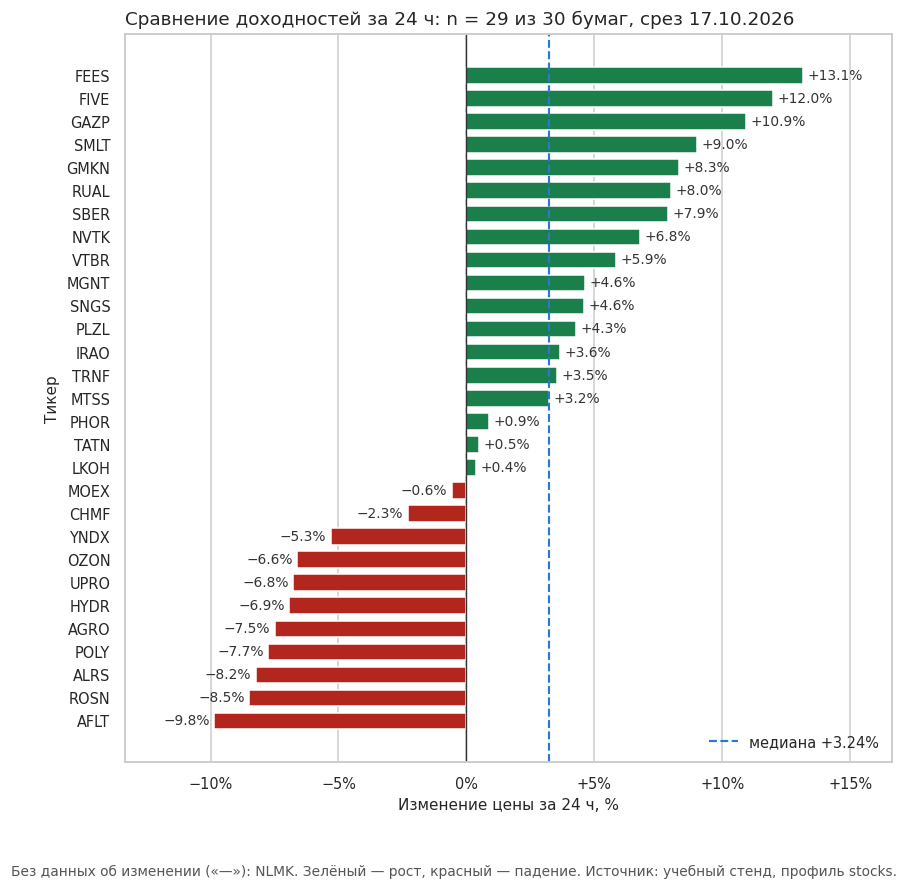

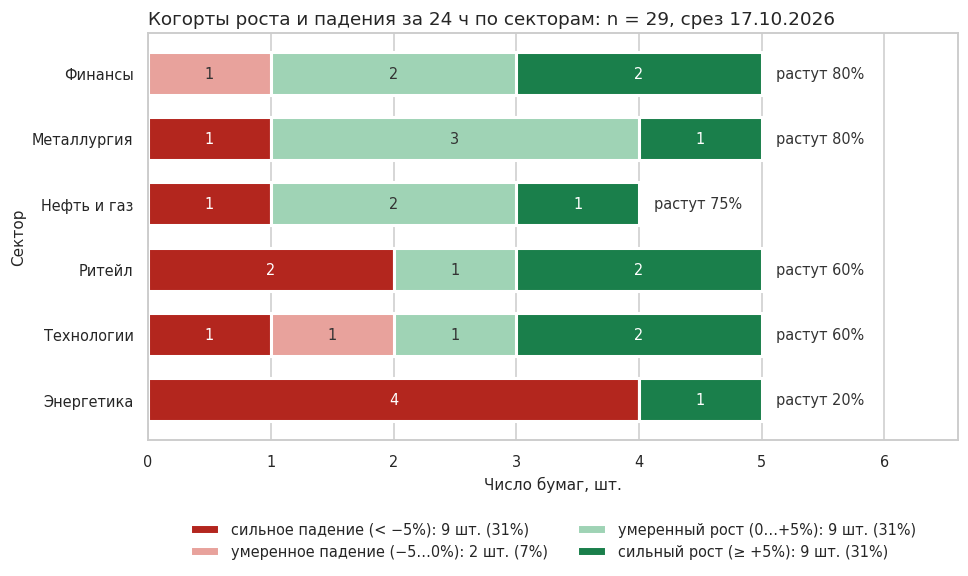

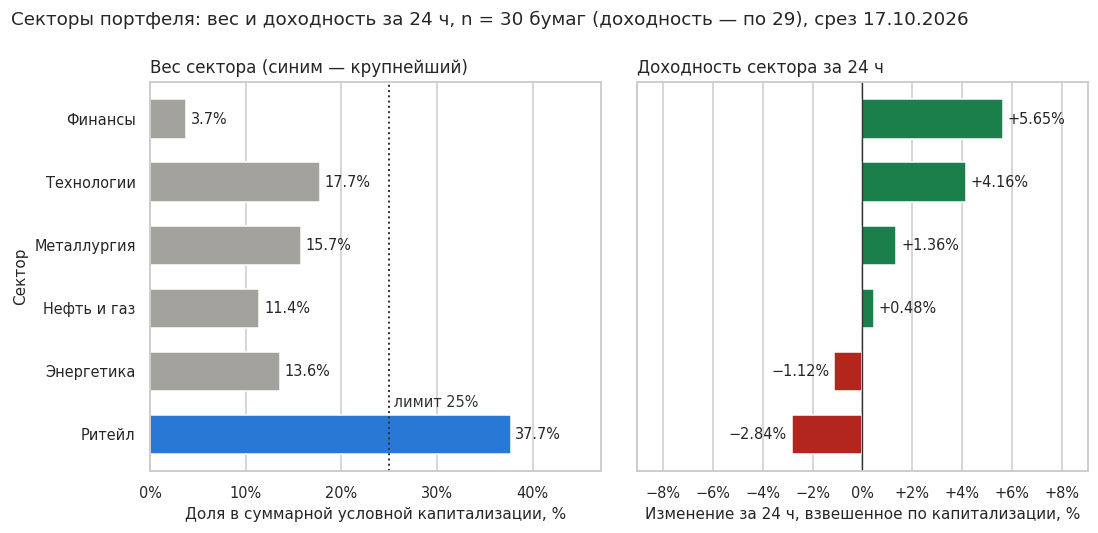

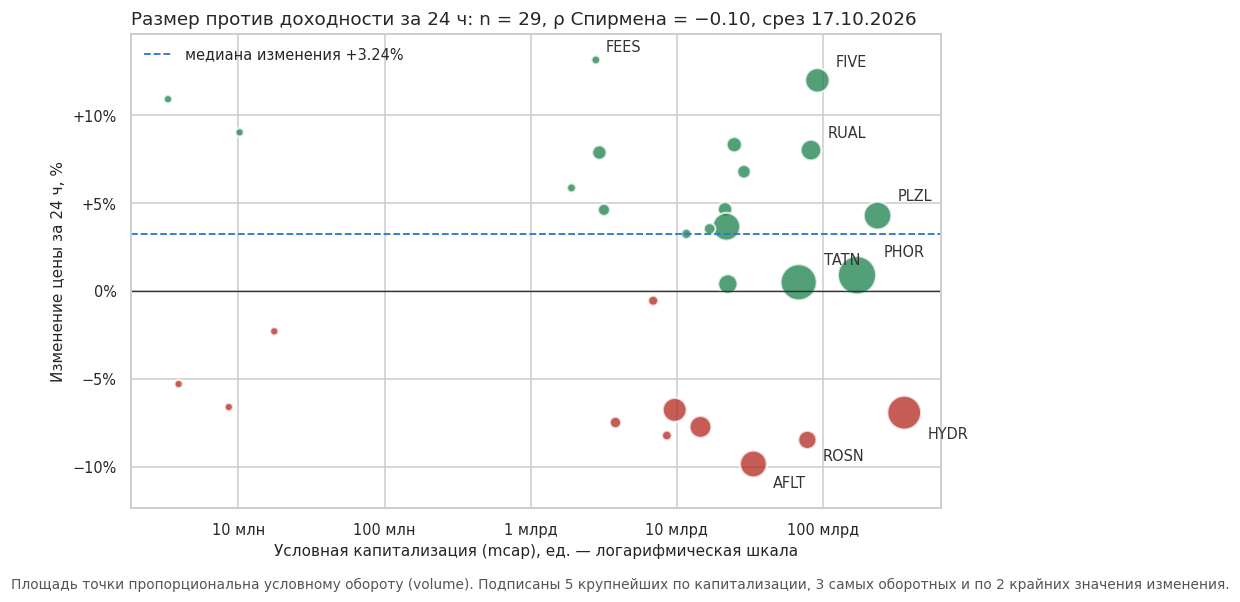

Графики сохранены в /content/lr1/charts: 01_returns_24h.png, 02_cohorts_by_sector.png, 03_sector_weight_return.png, 04_size_vs_return.png

ОТЧЁТ ДЛЯ ЛПР · вариант 2 «Фондовые индексы АТР» · профиль стенда «stocks» · срез 17.10.2026

ЧТО СОБРАНО
  30 уникальных позиций учебной витрины (Playwright → HTML → lxml/XPath), 6 секторов.
  Изменение за 24 ч распознано у 29 из 30 (пропуск: NLMK), цена — у 29 из 30.
  Данные модельные: изменение доступно только за одни сутки, volume/mcap — условные показатели стенда,
  поля «регион/страна» в стенде нет, поэтому разрез «по регионам» заменён разрезом по секторам.

ТРИ НАБЛЮДЕНИЯ
  1. Рынок за сутки поляризован: выросли 18 из 29 бумаг (62%), медиана +3.24%,
     среднее +1.29%, σ = 6.99%, межквартильный размах 13.39%
     (от −9.85% у AFLT до +13.14% у FEES).
     Хвосты симметричны: «сильный рост (≥ +5%)» — 9 бумаг (31%),
     «сильное падение (< −5%)» — 9 (31%); в коридоре ±5% только 11 (38%).
  2. Результат портфеля определяет одна бумага: HYDR —

In [8]:
#@title Шаг 7. Бизнес-анализ и визуализация { display-mode: "form" }
from matplotlib.ticker import FuncFormatter, MultipleLocator, PercentFormatter

# ------------------------------------------------------------------ TODO 7.1
# Палитра: зелёный/красный — только рост/падение; синий — единственный акцент; серый — нейтральный.
GREEN, RED, ACCENT, NEUTRAL, INK = "#1a7f4b", "#b3261e", "#2a78d6", "#a3a29c", "#333333"
COHORT_COLORS = ["#b3261e", "#e8a29c", "#9fd3b5", "#1a7f4b"]
COHORT_BINS = [-np.inf, -0.05, 0, 0.05, np.inf]
SECTOR_CAP, NAME_CAP = 0.25, 0.10     # модельные лимиты концентрации для ребалансировки
COHORT_LABELS = ["сильное падение (< −5%)", "умеренное падение (−5…0%)",
                 "умеренный рост (0…+5%)", "сильный рост (≥ +5%)"]
plt.rcParams.update({"font.size": 10, "axes.titlesize": 12, "axes.labelsize": 10,
                     "xtick.labelsize": 9.5, "ytick.labelsize": 9.5, "legend.fontsize": 9.5})
CHART_DIR = WORK_DIR / "charts"
CHART_DIR.mkdir(exist_ok=True)
STAMP = COLLECTED_AT.strftime("%d.%m.%Y")
pct_signed = FuncFormatter(lambda v, _: f"{v:+.0%}".replace("-", "−") if v else "0%")

def signed(v, digits=1):
    return f"{v:+.{digits}%}".replace("-", "−")

def save(fig, name):
    fig.savefig(CHART_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()

chg = df.dropna(subset=["change_24h"]).copy()
chg["cohort"] = pd.cut(chg["change_24h"], bins=COHORT_BINS, labels=COHORT_LABELS, right=False)
n_all, n_chg = len(df), len(chg)
missing_chg = ", ".join(df.loc[df["change_24h"].isna(), "ticker"]) or "нет"
med_chg = chg["change_24h"].median()

# --- График 1. Сравнение доходностей: изменение за 24 ч по каждой бумаге
s1 = chg.sort_values("change_24h")
fig, ax = plt.subplots(figsize=(9, 8.6))
bars = ax.barh(s1["ticker"], s1["change_24h"], height=0.72,
               color=np.where(s1["change_24h"] >= 0, GREEN, RED))
ax.bar_label(bars, labels=[signed(v) for v in s1["change_24h"]], padding=3, fontsize=9, color=INK)
ax.axvline(0, color=INK, lw=0.9)
ax.axvline(med_chg, color=ACCENT, ls="--", lw=1.4, label=f"медиана {signed(med_chg, 2)}")
lo, hi = s1["change_24h"].min(), s1["change_24h"].max()
ax.set_xlim(lo - 0.035, hi + 0.035)
ax.xaxis.set_major_formatter(pct_signed)
ax.set_xlabel("Изменение цены за 24 ч, %")
ax.set_ylabel("Тикер")
ax.set_title(f"Сравнение доходностей за 24 ч: n = {n_chg} из {n_all} бумаг, срез {STAMP}", loc="left")
ax.legend(loc="lower right", frameon=False)
ax.grid(axis="y", visible=False)
fig.text(0.01, -0.01, f"Без данных об изменении («—»): {missing_chg}. Зелёный — рост, красный — падение. "
         "Источник: учебный стенд, профиль stocks.", fontsize=9, color="#555")
save(fig, "01_returns_24h.png")

# --- График 2. Когорты роста и падения по секторам (секторы — замена недоступным регионам)
cohort_tab = pd.crosstab(chg["sector"], chg["cohort"].astype(str)).reindex(columns=COHORT_LABELS, fill_value=0)
share_up_sector = (chg["change_24h"] >= 0).groupby(chg["sector"]).mean()
order2 = share_up_sector.sort_values().index
cohort_tab = cohort_tab.loc[order2]
cohort_total = chg["cohort"].value_counts().reindex(COHORT_LABELS)
fig, ax = plt.subplots(figsize=(9.5, 4.8))
left = np.zeros(len(cohort_tab))
for label, color in zip(COHORT_LABELS, COHORT_COLORS):
    vals = cohort_tab[label].to_numpy()
    ax.barh(cohort_tab.index, vals, left=left, color=color, edgecolor="white", linewidth=2, height=0.66,
            label=f"{label}: {cohort_total[label]} шт. ({cohort_total[label] / n_chg:.0%})")
    for y, (l, v) in enumerate(zip(left, vals)):
        if v:
            ax.text(l + v / 2, y, str(v), ha="center", va="center", fontsize=9.5,
                    color="white" if color in (GREEN, RED) else INK)
    left += vals
for y, sector in enumerate(cohort_tab.index):
    ax.text(left[y] + 0.12, y, f"растут {share_up_sector[sector]:.0%}", va="center", fontsize=9.5, color=INK)
ax.set_xlim(0, left.max() + 1.6)
ax.set_xlabel("Число бумаг, шт.")
ax.set_ylabel("Сектор")
ax.set_title(f"Когорты роста и падения за 24 ч по секторам: n = {n_chg}, срез {STAMP}", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, frameon=False)
ax.grid(axis="y", visible=False)
save(fig, "02_cohorts_by_sector.png")

# --- График 3. Секторы: вес в условной капитализации и доходность, взвешенная по капитализации
s3 = by_sector.sort_values("cap_weighted_change")
fig, (ax_w, ax_r) = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True, gridspec_kw={"wspace": 0.08})
w_colors = [ACCENT if v == s3["mcap_share"].max() else NEUTRAL for v in s3["mcap_share"]]
b = ax_w.barh(s3["sector"], s3["mcap_share"], color=w_colors, height=0.62)
ax_w.bar_label(b, labels=[f"{v:.1%}" for v in s3["mcap_share"]], padding=3, fontsize=9.5)
ax_w.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax_w.set_xlim(0, s3["mcap_share"].max() * 1.25)
ax_w.axvline(SECTOR_CAP, color=INK, ls=":", lw=1.3)
ax_w.text(SECTOR_CAP, 0.5, f" лимит {SECTOR_CAP:.0%}", fontsize=9.5, color=INK, va="center")
ax_w.set_xlabel("Доля в суммарной условной капитализации, %")
ax_w.set_ylabel("Сектор")
ax_w.set_title("Вес сектора (синим — крупнейший)", loc="left", fontsize=11)
b = ax_r.barh(s3["sector"], s3["cap_weighted_change"], height=0.62,
              color=np.where(s3["cap_weighted_change"] >= 0, GREEN, RED))
ax_r.bar_label(b, labels=[signed(v, 2) for v in s3["cap_weighted_change"]], padding=3, fontsize=9.5)
ax_r.axvline(0, color=INK, lw=0.9)
span = max(s3["cap_weighted_change"].abs().max(), 0.01)
ax_r.set_xlim(-span * 1.6, span * 1.6)
ax_r.xaxis.set_major_locator(MultipleLocator(0.02))
ax_r.xaxis.set_major_formatter(pct_signed)
ax_r.set_xlabel("Изменение за 24 ч, взвешенное по капитализации, %")
ax_r.set_title("Доходность сектора за 24 ч", loc="left", fontsize=11)
for a in (ax_w, ax_r):
    a.grid(axis="y", visible=False)
fig.suptitle(f"Секторы портфеля: вес и доходность за 24 ч, n = {n_all} бумаг (доходность — по {n_chg}), срез {STAMP}",
             x=0.01, ha="left", fontsize=12, y=1.02)
save(fig, "03_sector_weight_return.png")

# --- График 4. Связь размера и доходности: капитализация (лог) × изменение, площадь точки ~ обороту
s4 = chg.dropna(subset=["mcap_value"])
rho = s4["mcap_value"].rank().corr(s4["change_24h"].rank())      # Спирмен без scipy
sizes = 30 + 600 * s4["volume_value"] / s4["volume_value"].max()
fig, ax = plt.subplots(figsize=(9.5, 5.6))
ax.scatter(s4["mcap_value"], s4["change_24h"], s=sizes, alpha=0.75, edgecolor="white", linewidth=1.5,
           color=np.where(s4["change_24h"] >= 0, GREEN, RED))
ax.axhline(0, color=INK, lw=0.9)
ax.axhline(med_chg, color=ACCENT, ls="--", lw=1.2, label=f"медиана изменения {signed(med_chg, 2)}")
ax.set_xscale("log")
ax.set_ylim(s4["change_24h"].min() - 0.025, s4["change_24h"].max() + 0.015)   # место под подписи
to_label = pd.concat([s4.nlargest(5, "mcap_value"), s4.nlargest(3, "volume_value"),
                      s4.nlargest(2, "change_24h"), s4.nsmallest(2, "change_24h")]).drop_duplicates("ticker")
for _, r in to_label.iterrows():
    off = 3 + np.sqrt(sizes[r.name] / np.pi)              # радиус точки в пунктах
    dy = off * 0.6 if r["change_24h"] >= 0 else -off * 0.6   # падающие — подпись снизу, растущие — сверху
    ax.annotate(r["ticker"], (r["mcap_value"], r["change_24h"]), xytext=(off, dy), textcoords="offset points",
                va="bottom" if dy > 0 else "top",
                fontsize=9.5, color=INK)
ax.yaxis.set_major_formatter(pct_signed)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v / 1e9:g} млрд" if v >= 1e9 else f"{v / 1e6:g} млн"))
ax.set_xlabel("Условная капитализация (mcap), ед. — логарифмическая шкала")
ax.set_ylabel("Изменение цены за 24 ч, %")
ax.set_title(f"Размер против доходности за 24 ч: n = {len(s4)}, ρ Спирмена = {rho:+.2f}, срез {STAMP}".replace("-", "−"),
             loc="left")
ax.legend(loc="upper left", frameon=False)
fig.text(0.01, -0.02, "Площадь точки пропорциональна условному обороту (volume). Подписаны 5 крупнейших по "
         "капитализации, 3 самых оборотных и по 2 крайних значения изменения.", fontsize=9, color="#555")
save(fig, "04_size_vs_return.png")
PLOTS_DONE = True
print(f"Графики сохранены в {CHART_DIR}: {', '.join(sorted(p.name for p in CHART_DIR.glob('*.png')))}")

# ------------------------------------------------------------------ TODO 7.2

def cap_weighted(frame):
    return (frame["change_24h"] * frame["mcap_value"]).sum() / frame["mcap_value"].sum()

up = chg["change_24h"] >= 0
ew_mean = chg["change_24h"].mean()
cw_total = cap_weighted(chg)
iqr = chg["change_24h"].quantile(0.75) - chg["change_24h"].quantile(0.25)
best, worst = chg.loc[chg["change_24h"].idxmax()], chg.loc[chg["change_24h"].idxmin()]
strong_fall = chg.loc[chg["cohort"] == COHORT_LABELS[0]].sort_values("change_24h")
strong_up = chg.loc[chg["cohort"] == COHORT_LABELS[3]].sort_values("change_24h", ascending=False)
n_moderate = n_chg - len(strong_fall) - len(strong_up)

weights = df["mcap_value"] / df["mcap_value"].sum()
hhi = (weights ** 2).sum()
top1 = df.loc[df["mcap_value"].idxmax()]
cw_ex_top1 = cap_weighted(chg[chg["ticker"] != top1["ticker"]])
share_top5_mcap = df.nlargest(5, "mcap_value")["mcap_value"].sum() / df["mcap_value"].sum()
names_over = df.assign(w=weights).loc[lambda x: x["w"] > NAME_CAP].sort_values("w", ascending=False)
sectors_over = by_sector.loc[by_sector["mcap_share"] > SECTOR_CAP].sort_values("mcap_share", ascending=False)

top_sec, low_sec = by_sector.iloc[0], by_sector.iloc[-1]
heavy = by_sector.loc[by_sector["mcap_share"].idxmax()]
heavy_up = (chg.loc[chg["sector"] == heavy["sector"], "change_24h"] >= 0).mean()
weak_breadth = by_sector.loc[by_sector["share_up"].idxmin()]
broad = by_sector.loc[(by_sector["share_up"] >= 0.75) & (by_sector["cap_weighted_change"] > 0)]
top5_vol = df.nlargest(5, "volume_value")
liquid_cut = df["volume_value"].median()
rho_txt = f"{rho:+.2f}".replace("-", "−")

def fmt_list(frame, col, fmt):
    return ", ".join(f"{t} {fmt(v)}" for t, v in zip(frame["ticker"] if "ticker" in frame else frame["sector"],
                                                     frame[col]))

REPORT = f"""
ОТЧЁТ ДЛЯ ЛПР · вариант {VARIANT} «{CFG['domain']}» · профиль стенда «{CFG['profile']}» · срез {STAMP}

ЧТО СОБРАНО
  {n_all} уникальных позиций учебной витрины (Playwright → HTML → lxml/XPath), {df['sector'].nunique()} секторов.
  Изменение за 24 ч распознано у {n_chg} из {n_all} (пропуск: {missing_chg}), цена — у {int(df['price_value'].notna().sum())} из {n_all}.
  Данные модельные: изменение доступно только за одни сутки, volume/mcap — условные показатели стенда,
  поля «регион/страна» в стенде нет, поэтому разрез «по регионам» заменён разрезом по секторам.

ТРИ НАБЛЮДЕНИЯ
  1. Рынок за сутки поляризован: выросли {int(up.sum())} из {n_chg} бумаг ({up.mean():.0%}), медиана {signed(med_chg, 2)},
     среднее {signed(ew_mean, 2)}, σ = {chg['change_24h'].std():.2%}, межквартильный размах {iqr:.2%}
     (от {signed(worst['change_24h'], 2)} у {worst['ticker']} до {signed(best['change_24h'], 2)} у {best['ticker']}).
     Хвосты симметричны: «сильный рост (≥ +5%)» — {len(strong_up)} бумаг ({len(strong_up) / n_chg:.0%}),
     «сильное падение (< −5%)» — {len(strong_fall)} ({len(strong_fall) / n_chg:.0%}); в коридоре ±5% только {n_moderate} ({n_moderate / n_chg:.0%}).
  2. Результат портфеля определяет одна бумага: {top1['ticker']} — {top1['mcap_value'] / df['mcap_value'].sum():.1%} суммарной
     капитализации, 5 крупнейших — {share_top5_mcap:.0%}, HHI = {hhi:.3f} (≈ {1 / hhi:.1f} «равных» бумаг из {n_all}).
     Взвешенная по капитализации доходность {signed(cw_total, 2)} против {signed(ew_mean, 2)} у равновзвешенного портфеля;
     без {top1['ticker']} ({signed(top1['change_24h'], 2)}) взвешенная доходность была бы {signed(cw_ex_top1, 2)}.
  3. Секторы расходятся: лучший — «{top_sec['sector']}» {signed(top_sec['cap_weighted_change'], 2)} (растут {top_sec['share_up']:.0%}
     бумаг), но его вес лишь {top_sec['mcap_share']:.1%}; крупнейший по весу — «{heavy['sector']}» ({heavy['mcap_share']:.1%}) —
     {signed(heavy['cap_weighted_change'], 2)}, хотя растут {heavy_up:.0%} его бумаг. Самая узкая база роста — «{weak_breadth['sector']}»:
     растут {weak_breadth['share_up']:.0%} бумаг, медиана {signed(weak_breadth['median_change'], 2)}. Связь размера и доходности
     слабая (ρ Спирмена = {rho_txt}).

РЕШЕНИЯ (на учебной модели; для реального портфеля — после проверки на исторических данных)
  1. Лимиты концентрации при ребалансировке: сектор ≤ {SECTOR_CAP:.0%}, бумага ≤ {NAME_CAP:.0%} портфеля. Сейчас лимиты превышают
     секторы: {fmt_list(sectors_over, 'mcap_share', '{:.1%}'.format) or 'нет'}; бумаги: {fmt_list(names_over, 'w', '{:.1%}'.format) or 'нет'}.
     Ожидаемый эффект: результат портфеля перестаёт зависеть от одной бумаги. Проверка: HHI и эффективное
     число бумаг до/после, разрыв доходности «по капитализации − равные веса» и tracking error на истории.
  2. Высвобожденный вес — в секторы с широким ростом и положительной взвешенной доходностью
     ({fmt_list(broad, 'cap_weighted_change', lambda v: signed(v, 2)) or 'нет'}); «{weak_breadth['sector']}» — на наблюдение, без докупок.
     Однодневный сигнал не основание для сделки: решение принимается, если знак сохраняется на окне
     20–60 торговых дней. Проверка: бэктест против капитализационного и равновзвешенного бенчмарков.
  3. Правило когорт и исполнение: бумаги «сильного падения» ({', '.join(strong_fall['ticker'])}) — на разбор
     риск-комитета до любых докупок; сделки ребалансировки — через бумаги с условным оборотом выше медианы
     ({liquid_cut / 1e6:,.0f} млн ед.; топ-5 по обороту: {', '.join(top5_vol['ticker'])}). Ожидаемый эффект — контроль просадок
     и меньшие издержки. Проверка: максимальная просадка портфеля и проскальзывание по фактическим сделкам.

ОГРАНИЧЕНИЯ
  Одни сутки — не доходность в инвестиционном смысле: нужны ряды цен (минимум 1–3 года дневных закрытий),
  волатильность и корреляции. Секторная принадлежность в стенде условна (назначается по кругу: например,
  {df.loc[df['sector'] == heavy['sector'], 'ticker'].iloc[0]} отнесён к «{heavy['sector']}»). Для задачи «индексы АТР» требуются уровни индексов
  (Nikkei 225, Hang Seng, Shanghai Composite, KOSPI, S&P/ASX 200, Nifty 50 и др.), привязка к стране/региону,
  валютные курсы для пересчёта доходности в базовую валюту и текущие веса портфеля.
"""
print(REPORT)

**Как интерпретировать результат.** Сначала назовите фактически рассчитанные показатели, размер выборки и тип учебных данных. Затем объясните, какие различия между позициями или категориями они показывают. **Не утверждайте**, что выявлены реальные складские дефициты, инвестиционные раунды, биржевые риски или продажи, если таких сведений в стенде нет. Практическую рекомендацию формулируйте как **решение на основе учебной модели**, а необходимые для реального применения дополнительные данные перечислите отдельно.


## Заключение по варианту 2 «Фондовые индексы АТР»

### Что собрано и рассчитано

Playwright собрал **30 из 30** позиций учебной витрины, профиль `stocks`, 6 секторов. Данные извлечены из HTML через `lxml`/XPath. Распознаны: изменение за 24 ч — 29 из 30 (у NLMK «—»), цена — 29 из 30 (у TATN «n/a»), `volume`, `mcap` и дата листинга — 30 из 30. Пропуски сохранены как `NaN`, проценты хранятся долями единицы.

Рассчитаны только показатели, для которых в стенде есть исходные поля:

* доля растущих бумаг, медиана, среднее, σ и межквартильный размах изменения за 24 ч;
* когорты роста и падения с порогами ±5 %;
* по секторам: вес в условной капитализации, доходность, взвешенная по капитализации, доля растущих бумаг;
* концентрация: доля крупнейших бумаг и индекс Херфиндаля — Хиршмана (HHI);
* ранговая корреляция Спирмена между размером и доходностью.

**Замена недоступной метрики.** В бизнес-задаче нужна ребалансировка *регионального* портфеля индексов. В стенде нет поля «регион/страна» и нет рядов доходности за период, есть только изменение за одни сутки. Поэтому вместо региональных «рукавов» портфеля используются **секторы** стенда. Смысл показателя не меняется: это категория внутри портфеля с весом и доходностью. Региональную доходность по этим данным посчитать нельзя.

### Три наблюдения

1. **Рынок за сутки поляризован.** Выросли 18 из 29 бумаг (62 %). Медиана +3,24 %, среднее +1,29 %, σ = 6,99 %, межквартильный размах 13,39 % (от −9,85 % у AFLT до +13,14 % у FEES). Хвосты симметричны: «сильный рост ≥ +5 %» и «сильное падение < −5 %» — по 9 бумаг (по 31 %), в коридоре ±5 % только 11 бумаг (38 %).
2. **Результат портфеля определяет одна бумага.** На HYDR приходится 26,0 % условной капитализации, на 5 крупнейших бумаг — 68 %. HHI = 0,130, то есть портфель ведёт себя как ≈ 7,7 «равных» бумаги из 30. Портфель, взвешенный по капитализации, дал **−0,03 %**, а равновзвешенный — **+1,29 %**. Без HYDR (−6,93 %) взвешенная доходность была бы **+2,55 %**.
3. **Секторы расходятся, и вес не совпадает с результатом.** Лучший сектор — «Финансы»: +5,65 %, растут 80 % бумаг, но его вес всего 3,7 %. Крупнейший сектор «Ритейл» (37,7 % веса) дал −2,84 %, хотя растут 60 % его бумаг: результат тянет вниз HYDR. Самая узкая база роста у «Энергетики»: растут 20 % бумаг, медиана −7,74 %. Связь размера и доходности слабая (ρ Спирмена = −0,10).

### Рекомендации (решения на учебной модели)

| № | Решение | Обоснование (числа) | Ожидаемый эффект | Как проверить |
|---|---|---|---|---|
| 1 | Ввести лимиты концентрации при ребалансировке: сектор ≤ 25 %, бумага ≤ 10 % | Лимиты превышают «Ритейл» (37,7 %), HYDR (26,0 %), PLZL (17,1 %), PHOR (12,4 %). Разрыв между взвешенным и равновзвешенным портфелем −1,3 п.п. | Результат портфеля перестаёт зависеть от одной бумаги | HHI и эффективное число бумаг до и после; tracking error и разрыв «капитализация − равные веса» на истории |
| 2 | Высвобожденный вес направить в секторы с широким ростом, «Энергетику» оставить на наблюдении без докупок | «Финансы» +5,65 %, «Металлургия» +1,36 %, «Нефть и газ» +0,48 %: в каждом растут ≥ 75 % бумаг. В «Энергетике» растут 20 % бумаг | Вес смещается к секторам, где рост широкий, а не держится на одной-двух бумагах | Решение принимается, только если сигнал держится на окне 20–60 торговых дней; бэктест против капитализационного и равновзвешенного бенчмарков |
| 3 | Бумаги когорты «сильное падение» отправлять на разбор риск-комитета до докупок; сделки ребалансировки проводить через бумаги с оборотом выше медианы | 9 бумаг в когорте < −5 %. Медиана условного оборота 384 млн ед., топ-5 по обороту: PHOR, TATN, HYDR, IRAO, PLZL | Контроль просадок, меньшие издержки исполнения | Максимальная просадка портфеля; проскальзывание по фактическим сделкам |

### Ограничения интерпретации

* Данные стенда **модельные**. Тикеры совпадают с российскими эмитентами, но цены, сектора и показатели сгенерированы. Сектор назначается по кругу: например, GMKN отнесён к «Ритейлу». Выводы нельзя переносить на реальный рынок.
* Изменение за 24 ч — это не доходность в инвестиционном смысле. Однодневный сигнал шумный, по нему нельзя оценить волатильность, корреляции или коэффициент Шарпа.
* `volume` и `mcap` — условные показатели стенда без единиц. Они использованы только как относительные веса и мера ликвидности.
* **Для реальной задачи нужны:**
  * дневные уровни индексов АТР за 1–3 года (Nikkei 225, TOPIX, Hang Seng, Shanghai Composite, KOSPI, S&P/ASX 200, Nifty 50, TAIEX, Straits Times);
  * страна или регион каждого индекса;
  * курсы валют, чтобы пересчитать доходность в базовую валюту;
  * текущие и целевые веса портфеля, ограничения инвестдекларации, издержки и ликвидность инструментов, через которые реализуется экспозиция (ETF, фьючерсы).

### Реальная площадка: Investing.com — Asia/Pacific indices (без парсинга)

* **Назначение.** Агрегатор котировок. Раздел азиатских индексов — динамическая таблица с последним значением, изменением и % изменения, котировки обновляются без перезагрузки страницы.
* **robots.txt** (просмотрен 16.10.2026). Для `User-agent: *` закрыты около 26 путей: `/admin`, `/login`, `/members`, `/research/`, `/pro/` с отдельными исключениями, `/cdn-cgi/` и др. Для индексов закрыты только страницы графиков `/indices/*?page=chart`. Сам список индексов robots.txt не запрещает, `Crawl-delay` не задан.
* **Пользовательское соглашение и Risk Disclosure.** Использование, хранение, воспроизведение, изменение, передача и распространение данных сайта запрещены без явного письменного разрешения Fusion Media и (или) поставщика данных. Данные «не обязательно в реальном времени и не обязательно точны», цены могут приходить от маркет-мейкеров, а не с биржи, и являются индикативными. Значит, разрешение robots.txt не даёт права на автоматический сбор и повторное использование данных: для аналитического продукта нужен лицензированный источник.
* **XHR/API.** Публичного документированного API у площадки нет. Внутренние XHR- и WebSocket-эндпоинты в рамках работы **не устанавливались**, это ограничение исследования. Запрос страницы раздела инструментом веб-выборки, а не браузером, вернул HTTP 404. Почему — страница перемещена или автоматическим клиентам отдаётся иной ответ — установить не удалось. Обход защит не предпринимался.

### Легальные источники аналогичных данных

* **MOEX ISS API** (`iss.moex.com`). Официальный интерфейс Московской биржи: JSON, XML, CSV, история торгов, например `/iss/history/engines/stock/markets/shares/securities/{SECID}.json`, и индексы Мосбиржи. Без подписки данные о ходе торгов отдаются с задержкой 15 минут. Распространение и коммерческое использование регулируются правилами использования биржевой информации Мосбиржи. Источник подходит для бумаг профиля `stocks` и российских бенчмарков, но **не содержит индексов АТР**.
* **Alpha Vantage.** REST API с бесплатным ключом. Лимит бесплатного тарифа — 25 запросов в сутки и 5 в минуту. Дневные ряды акций и ETF доступны, а индексные данные, по ряду источников, относятся к премиальным эндпоинтам. Практичный путь для задачи АТР — **ETF-прокси** страновых рынков: EWJ (Япония), MCHI/FXI (Китай), EWH (Гонконг), EWY (Корея), EWA (Австралия), INDA (Индия), EWT (Тайвань), EWS (Сингапур). Их дневные закрытия вместе с курсами валют дают региональные доходности; 8 рядов укладываются в суточный лимит.
* **Для промышленного решения** нужны лицензированные данные: от индексных провайдеров (JPX, Hang Seng Indexes, S&P DJI) или вендоров (LSEG, Bloomberg).

## Таблица вариантов (30 вариантов)

Номер варианта выдаёт преподаватель; параметры подставляются в код автоматически по значению `VARIANT`. Столбец «Профиль стенда» задаёт набор данных учебной витрины — это обязательная часть работы. Столбцы «Реальная площадка» и «Легальный источник» относятся к краткой исследовательской части, **без обязательного сбора с внешнего сайта**. Достаточно описать ограничения автоматизированного доступа, возможный XHR/API (если он публично доступен и удалось его установить) и разрешённые аналоги. Аналитическая задача указывает бизнес-контекст: если отдельных показателей нет в учебном стенде, используйте доступные поля и явно объясните ограничение.

| № | Доменная область | Профиль стенда | Реальная площадка (разбор ограничений) | Легальный источник тех же данных | Аналитическая задача и решение |
|---:|---|---|---|---|---|
| 1 | Криптовалютный арбитраж | `crypto` | CoinMarketCap — раздел Cryptocurrencies | CoinGecko API (/coins/markets) | Топ-10 по обороту, разброс суточного изменения; решение: где держать лимиты маркет-мейкера |
| 2 | Фондовые индексы АТР | `stocks` | Investing.com — Asia/Pacific indices | MOEX ISS API, Alpha Vantage | Сравнение доходностей, когорты роста и падения; решение: ребалансировка регионального портфеля |
| 3 | Мониторинг цен на технологические металлы | `metals` | Trading Economics — Commodities | World Bank Commodity Price Data (Pink Sheet) | Топ по обороту и волатильности; решение: сроки хеджирования закупок |
| 4 | Ценовая разведка маркетплейса: смартфоны | `ecom` | Агрегатор цен категории «Смартфоны» | Открытые фиды поставщиков, API маркетплейса продавца | Ценовые сегменты и доля дефицита; решение: цена входа в категорию |
| 5 | Трекинг раундов венчурных сделок | `startups` | Crunchbase — Funding Rounds | OpenAlex, Dealroom API (по подписке), данные ЕГРЮЛ | Распределение размеров раундов, топ-инвесторы; решение: фокус отраслевого фонда |
| 6 | Ликвидность DeFi-протоколов | `crypto` | DeFiLlama — TVL rankings | DefiLlama API (открытый) | TVL и оборот в логарифмических шкалах; решение: лимиты на протокол |
| 7 | Голубые фишки российского рынка | `stocks` | Investing.com — Russian stocks | MOEX ISS API (iss.moex.com) | Топ по обороту, медиана изменения; решение: состав торговой корзины дня |
| 8 | Драгоценные металлы и хеджирование | `metals` | Kitco — Live spot prices | LBMA открытые котировки, ЦБ РФ учётные цены | Динамика и разброс; решение: доля металлов в резерве |
| 9 | Мониторинг цен на ноутбуки | `ecom` | Витрина категории «Ноутбуки» | API прайс-агрегатора продавца | Медианы по сегментам, ценовые кластеры; решение: позиционирование новой линейки |
| 10 | Скоринг стартап-экосистемы региона | `startups` | Dealroom — региональные дашборды | OpenAlex, Росстат, ЕГРЮЛ | Когорты по темпу роста; решение: приоритеты акселератора |
| 11 | Стейблкоины и риск депега | `crypto` | CoinMarketCap — Stablecoins | CoinGecko API | Отклонение от номинала, объёмы; решение: лимиты казначейства |
| 12 | Европейские индексы и открытие торгов | `stocks` | Investing.com — European indices | Alpha Vantage, Stooq | Утренние гэпы, распределение; решение: тайминг заявок |
| 13 | Аккумуляторные металлы и цепочка поставок | `metals` | SMM — Battery metals | USGS Mineral Commodity Summaries | Волатильность лития и кобальта; решение: пересмотр закупочных контрактов |
| 14 | Бытовая техника: акции конкурентов | `ecom` | Витрина категории «Бытовая техника» | Фиды партнёрских программ | Глубина скидок, доля позиций в наличии; решение: календарь промо |
| 15 | FinTech-стартапы: динамика найма | `startups` | AngelList / Wellfound — Jobs | «Работа в России» (opendata.trudvsem.ru) | Число вакансий против оценки; решение: выбор объекта для partnership |
| 16 | NFT и игровые токены | `crypto` | CoinGecko — Gaming category | CoinGecko API | Топ по обороту, хвосты распределения; решение: отсев неликвида |
| 17 | Азиатские IT-эмитенты | `stocks` | Yahoo Finance — Screener | Alpha Vantage, Nasdaq Data Link | Капитализация против оборота; решение: включение в watchlist |
| 18 | Редкоземельные элементы и импортозависимость | `metals` | Trading Economics — Rare earth | USGS, World Bank | Топ по цене и изменение; решение: стратегический запас |
| 19 | Аудиотехника: ассортиментная матрица | `ecom` | Витрина категории «Аудио» | API маркетплейса продавца | Медиана цены по секторам; решение: сокращение хвоста SKU |
| 20 | HealthTech: инвестиционная активность | `startups` | Crunchbase — HealthTech | OpenAlex, ClinicalTrials.gov API | Размер раунда и стадия; решение: вход в нишу |
| 21 | Кросс-биржевой спред по BTC | `crypto` | CoinMarketCap — Markets | Binance и Bybit публичные API | Спреды и обороты по площадкам; решение: маршрутизация ордеров |
| 22 | Дивидендные истории рынка РФ | `stocks` | Smart-lab — Дивиденды | MOEX ISS API | Доходность против капитализации; решение: дивидендный портфель |
| 23 | Промышленные металлы и энергопереход | `metals` | LME — Metals prices | World Bank Pink Sheet, ЦБ РФ | Когорты роста и падения; решение: индексация контрактов |
| 24 | Маркетплейс: мониторинг дефицита | `ecom` | Витрина «Все товары» | API продавца, фиды поставщиков | Доля отсутствующих позиций; решение: перераспределение закупки |
| 25 | EdTech: выручка и раунды | `startups` | HolonIQ — EdTech dashboards | OpenAlex, открытые отчёты фондов | Топ по оценке; решение: сделки M&A |
| 26 | Крипто-инфраструктура: L2-решения | `crypto` | L2BEAT — Scaling | L2BEAT API, DefiLlama API | TVL и рост; решение: выбор сети для интеграции |
| 27 | Американские техгиганты | `stocks` | Yahoo Finance — Most active | Alpha Vantage, Finnhub | Оборот и изменение; решение: наблюдение за концентрацией |
| 28 | Строительные материалы: индекс цен | `metals` | Trading Economics — Steel | Росстат, World Bank | Медианы и разброс; решение: бюджет строительного проекта |
| 29 | Недвижимость: мониторинг предложений | `ecom` | Агрегатор объявлений недвижимости | Открытые данные Росреестра, ЕМИСС | Распределение цен, когорты; решение: цена входа на локальный рынок |
| 30 | Комплексный мониторинг рыночной витрины (эталон) | `crypto` | CoinMarketCap — Cryptocurrencies | CoinGecko API (/coins/markets) | Топ-10 по обороту с выделением лидера, распределение изменения за 24 ч, когорты роста и падения, капитализация против оборота; решение: где концентрировать лимиты и что проверить до прогноза |

Минимум для зачёта по сбору: **все 30 позиций учебной витрины** (подгрузка работает), не менее **90 % распознанных значений** в предусмотренных самопроверкой колонках `volume_value` и `mcap_value`, **четыре содержательных графика по доступным полям** и управленческие выводы. В колонках `price_value` и `change_24h` намеренно встречаются пропуски: сохраняйте их как пропуски, а не как нули. Расчёт отсутствующих в стенде предметных метрик и парсинг внешнего сайта **не являются обязательными**.

## Критерии оценивания

**Единые для всех вариантов:** оценка выставляется по выполненным этапам на учебном стенде. Не снижаются баллы за отсутствие парсинга внешнего сайта и показателей, для которых в стенде не предусмотрены исходные данные; обязательны корректные альтернативные показатели и пояснение ограничений.

### Балльная структура (10 баллов)

| Блок | Что проверяется | Максимум |
|---|---|---:|
| 1. Окружение и запуск браузера | Корректная установка, флаги `--no-sandbox` и `--disable-dev-shm-usage`, реалистичный контекст, блокировка лишних ресурсов | 1,0 |
| 2. Обход препятствий | Закрытие cookie-баннера и модальных окон каскадом селекторов; работа при отсутствии баннера | 1,0 |
| 3. Ожидания | Явные ожидания вместо `time.sleep`; ожидание по числу строк при догрузке; корректный таймаут | 1,5 |
| 4. XPath и сбор | Устойчивые селекторы (`data-testid`, `contains`, оси), полнота выборки, разделение «браузер → HTML → lxml» | 2,0 |
| 5. Очистка и Excel | Суффиксы K/M/B, проценты долями, валюта, даты, пропуски как `NaN`; тесты функций; оформленная выгрузка | 2,0 |
| 6. Аналитика и графики | Четыре графика по доступным показателям варианта, корректные метрики, оформление | 1,5 |
| 7. Бизнес-вывод | 3 наблюдения с числами, 2–3 рекомендации, ограничения данных и краткий разбор реальной площадки | 1,0 |

### Шкала

| Баллы | Оценка | Содержательный смысл |
|---|---|---|
| 9,0–10,0 | **A** (отлично) | Скрипт устойчив, селекторы надёжны, очистка полная, выводы управленческие |
| 8,0–<9,0 | **B** (хорошо) | Данные собраны и очищены, есть шероховатости в обработке ошибок или оформлении |
| 7,0–<8,0 | **C** (удовлетворительно) | Сбор работает только «на удачном прогоне», ожидания частично на паузах |
| 6,0–<7,0 | **D** (зачтено с замечаниями) | Данные собраны неполно либо очистка теряет часть значений |
| <6,0 | **F** (не зачтено) | Скрипт не воспроизводится, данные собраны вручную или подменены |

### Требования к отказоустойчивости

Скрипт обязан переживать без падения ноутбука:

1. **Таймаут ожидания** (`TimeoutError` / `TimeoutException`) — перехват, сохранение скриншота и HTML, понятное сообщение о вероятной причине.
2. **Пустую выборку** — проверка `len(rows) == 0` до перехода к анализу, с указанием, какой селектор не сработал.
3. **Отсутствие оверлея** — отсутствие баннера не должно приводить к исключению.
4. **Частично заполненную строку** — отсутствующая ячейка даёт `None`, а не обрывает цикл.
5. **Нераспознанное значение** — `n/a`, `—`, пустая строка превращаются в `NaN`, но строка остаётся в выборке.
6. **Ограничение цикла догрузки** — максимальное число кликов и условие выхода при отсутствии роста.

### Требования к оформлению графиков

* заголовок с указанием объёма выборки (`n = …`) и периода;
* подписи обеих осей с единицами измерения (млн ₽, %, шт.);
* шрифт не мельче 9 пт, отсутствие наложения подписей;
* единая палитра: один акцентный цвет для выделяемой категории, нейтральный — для остальных; зелёный и красный только по смыслу «рост/падение»;
* опорные линии (ноль, медиана, порог) там, где они помогают читать график;
* логарифмическая шкала, если значения различаются на порядки, с явной пометкой в подписи оси;
* никаких «радужных» палитр на категориальных данных и трёхмерных эффектов.

### Штрафы

| Нарушение | Штраф |
|---|---:|
| `time.sleep()` вместо явных ожиданий в сценарии сбора | −1,0 |
| Данные получены вручную (скопированы), а не собраны скриптом | −4,0 |
| Попытка обхода капчи, Cloudflare или сбор за логином | работа не принимается |
| Сбор персональных данных | работа не принимается |
| Нет обработки исключений при сборе | −1,0 |
| Проценты сохранены как 2.5 вместо 0.025 или пропуски заменены нулями | −1,0 |
| Графики без подписей осей и единиц измерения | −0,5 |
| Ноутбук сдан без выводов ячеек | −1,0 |

### Перед самопроверкой

Убедитесь, что `raw_df` содержит 30 строк; функции очистки проходят тесты; Excel и `page.png` сохранены в `WORK_DIR`; четыре графика и выводы присутствуют в ноутбуке. **Скриншот после успешного сбора** добавьте в TODO 5.2 самостоятельно, так как автоматическое сохранение в заготовке описано только для таймаута.

Встроенная проверка **не является автоматическим выставлением оценки**. Её пункт «Явные ожидания вместо пауз» зависит от `COLLECT_SOURCE` (переменная не задаётся автоматически исходным шаблоном), а проверка графиков — от наличия открытых рисунков или `PLOTS_DONE`. Поэтому при ложном отрицательном результате приложите корректный код и сохранённые графики; **преподаватель оценивает фактическое выполнение**, а не только количество галочек. Исполняемую ячейку проверки изменять не требуется.


In [9]:
#@title Самопроверка перед сдачей { display-mode: "form" }
checks = []
def check(name, condition, hint=""):
    checks.append((name, bool(condition), hint))

check("Вариант выбран корректно", 1 <= VARIANT <= 30)
check("Браузер стартовал и страница открылась", bool(html) and len(html) > 1000)
check("Cookie-баннер обработан (или его не было)", "cookie-banner" not in html or USE_LIVE_TARGET,
      "баннер остался в DOM — клик не сработал")
check("Собраны все строки витрины (≥ 30)", len(raw_df) >= 30,
      "не отработала догрузка по кнопке «Показать ещё»")
check("Числовые поля распознаны не хуже 90 %",
      df["volume_value"].notna().mean() >= 0.9 and df["mcap_value"].notna().mean() >= 0.9)
check("Проценты приведены к долям единицы",
      df["change_24h"].dropna().abs().max() < 1.5 if df["change_24h"].notna().any() else False,
      "значение вроде 2.5 вместо 0.025 — забыли поделить на 100")
check("Пропуски не превратились в нули",
      df["price_value"].isna().sum() > 0 or df["change_24h"].isna().sum() > 0,
      "на стенде есть 'n/a' и '—': они должны остаться пропусками")
check("Файл Excel выгружен", EXCEL_PATH.exists() and EXCEL_PATH.stat().st_size > 4000)
check("Скриншот страницы сохранён как доказательство сбора", (WORK_DIR / "page.png").exists())
check("Явные ожидания вместо пауз", "time.sleep" not in globals().get("COLLECT_SOURCE", "time.sleep"),
      "уберите time.sleep из сценария сбора")
check("Построены графики", len(plt.get_fignums()) > 0 or globals().get("PLOTS_DONE", False),
      "выполните шаг 7 до самопроверки")

ok = sum(1 for _, passed, _ in checks if passed)
print(f"Выполнено: {ok} из {len(checks)}\n")
for name, passed, hint in checks:
    print(f"  {'✅' if passed else '❌'} {name}" + ("" if passed or not hint else f" — {hint}"))

Выполнено: 11 из 11

  ✅ Вариант выбран корректно
  ✅ Браузер стартовал и страница открылась
  ✅ Cookie-баннер обработан (или его не было)
  ✅ Собраны все строки витрины (≥ 30)
  ✅ Числовые поля распознаны не хуже 90 %
  ✅ Проценты приведены к долям единицы
  ✅ Пропуски не превратились в нули
  ✅ Файл Excel выгружен
  ✅ Скриншот страницы сохранён как доказательство сбора
  ✅ Явные ожидания вместо пауз
  ✅ Построены графики


## Дополнительное задание со звёздочкой (необязательно, до +2 баллов)

Выберите **одно** из предложенных ниже направлений и представьте воспроизводимый результат и его интерпретацию. Дополнительное задание не заменяет обязательные этапы ЛР1. Базовая шкала работы — **10 баллов**; дополнительные баллы рассматриваются преподавателем отдельно с учётом принятой в LMS максимальной оценки.


In [10]:
#@title Задание со звёздочкой (до +2 балла) { display-mode: "form" }
# A. Перехват сетевых запросов вместо разбора DOM.
#    Повесьте page.on("response", ...) и найдите XHR/fetch, который отдаёт те же данные в JSON.
#    Сравните время сбора и устойчивость двух подходов и объясните, когда DOM всё же необходим.
#
# B. Бесконечная прокрутка.
#    Замените кнопку «Показать ещё» на прокрутку (page.mouse.wheel) и реализуйте корректное
#    условие остановки: высота документа перестала расти в течение N итераций.
#
# C. Параллельный сбор.
#    Соберите пять профилей стенда одновременно через asyncio.gather и несколько контекстов.
#    Измерьте ускорение и объясните, почему контекстов должно быть больше, чем браузеров.
#
# D. Устойчивость к смене вёрстки.
#    Реализуйте «каскад селекторов»: data-testid → семантический XPath → текстовый поиск,
#    и тесты, которые ломают разметку (удалён атрибут, переименован класс).
#
# E. Мониторинг и сравнение срезов.
#    Сохраняйте снимки в parquet с меткой времени, реализуйте второй запуск и таблицу изменений:
#    новые позиции, изменение цены и оборота, выбывшие позиции.

### Выбрано направление D: устойчивость к смене вёрстки

**Идея.** Каждый селектор сценария задаётся не одной строкой, а каскадом уровней по убыванию надёжности. Используется первый уровень, который сработал. Если сработал запасной уровень, это фиксируется в журнале как сигнал «вёрстка изменилась, основной селектор пора обновить».

| Элемент | L1 `data-testid` | L2 семантический XPath | L3 текстовый поиск |
|---|---|---|---|
| Строки таблицы | `//tr[@data-testid='asset-row']` | строки тела таблицы, у которой есть шапка: `//table[thead/tr/th]/tbody/tr[td]` | строки таблицы, в шапке которой есть слово «тикер» (без учёта регистра) |
| Ячейка поля | `./td[@data-testid='price']` | столбец под заголовком с точным текстом «Цена»: оси `ancestor` и `preceding-sibling` | столбец под заголовком, содержащим «цен», «price»… (синонимы, без учёта регистра) |
| «Показать ещё» | `@data-testid='load-more'` | `@id='more'`, `@name`, `@aria-label` | текст «показать ещ», «load more»… |
| Cookie-баннер | `@data-testid='cookie-accept'` | `@id='accept'`, `@name`, `@aria-label` | текст «принять», «accept», «согласен» |

Защитные правила:

* Для строк выбирается уровень с **наибольшим** числом совпадений, а при равенстве — более надёжный. Так атрибут, пропавший у части строк, не обрежет выборку.
* Позиционные уровни L2 и L3 для ячеек срабатывают, только если в строке полный набор ячеек. Иначе значения съедут в соседние столбцы.
* Если каскад исчерпан, выводится явный отказ с причиной, а не пустые или чужие данные.

**Тесты.** Стенд копируется с намеренно сломанной разметкой (M1–M7). Для каждой копии проходит полный сценарий: браузер → явные ожидания → клики → HTML → lxml. Результат сравнивается с эталоном основного прогона по всем 30 × 9 = 270 ячейкам. Для контраста тот же сценарий выполняет **наивный парсер**: селекторы по классам, id и позициям столбцов, какие обычно копируют из DevTools.

127.0.0.1 - - [17/Oct/2026 01:04:59] "GET /star_d/stand_M0.html?variant=2&profile=stocks&delay=1200 HTTP/1.1" 200 -
127.0.0.1 - - [17/Oct/2026 01:05:03] "GET /star_d/stand_M0.html?variant=2&profile=stocks&delay=1200 HTTP/1.1" 200 -


M0 контроль: исходная вёрстка: строк 30, точность 100% (наивный парсер 100%) ✅


127.0.0.1 - - [17/Oct/2026 01:05:07] "GET /star_d/stand_M1.html?variant=2&profile=stocks&delay=1200 HTTP/1.1" 200 -
127.0.0.1 - - [17/Oct/2026 01:05:12] "GET /star_d/stand_M1.html?variant=2&profile=stocks&delay=1200 HTTP/1.1" 200 -


M1 удалён атрибут data-testid: строк 30, точность 100% (наивный парсер 100%) ✅
   ⚠ строки найдены уровнем «L2 семантический XPath» — обновите основной селектор
   ⚠ ячейки найдены запасными уровнями: L2×270


127.0.0.1 - - [17/Oct/2026 01:05:15] "GET /star_d/stand_M2.html?variant=2&profile=stocks&delay=1200 HTTP/1.1" 200 -
127.0.0.1 - - [17/Oct/2026 01:05:19] "GET /star_d/stand_M2.html?variant=2&profile=stocks&delay=1200 HTTP/1.1" 200 -


...

127.0.0.1 - - [17/Oct/2026 01:05:49] "GET /star_d/stand_M6.html?variant=2&profile=stocks&delay=1200 HTTP/1.1" 200 -
127.0.0.1 - - [17/Oct/2026 01:05:53] "GET /star_d/stand_M6.html?variant=2&profile=stocks&delay=1200 HTTP/1.1" 200 -


M6 нет <thead>, переименованы id кнопок + нет data-testid: строк 30, точность 100% (наивный парсер 40%) ✅
   ⚠ строки найдены уровнем «L3 текстовый поиск» — обновите основной селектор
   ⚠ ячейки найдены запасными уровнями: L2×270


127.0.0.1 - - [17/Oct/2026 01:05:55] "GET /star_d/stand_M7.html?variant=2&profile=stocks&delay=1200 HTTP/1.1" 200 -
127.0.0.1 - - [17/Oct/2026 01:06:01] "GET /star_d/stand_M7.html?variant=2&profile=stocks&delay=1200 HTTP/1.1" 200 -


M7 всё сразу: нет data-testid и шапки, новые id и классы: строк 0, точность 0% (наивный парсер 0%) ✅
   ⚠ каскад исчерпан: Page.wait_for_function: Timeout 4000ms exceeded.

Тестов пройдено: 8 из 8 за 68 с. Копии стенда: /content/lr1/star_d


,код,что сломано,строк,баннер,строки,кнопка,ячейки,точность каскада,точность наивного,итог
0,M0,контроль: исходная вёрстка,30,L1,L1,L1,L1×270,100%,100%,✅
1,M1,удалён атрибут data-testid,30,L2,L2,L2,L2×270,100%,100%,✅
2,M2,переименованы классы (css-хэши),30,L1,L1,L1,L1×270,100%,0%,✅
3,M3,переставлены столбцы «Объём» и «Капитализация»...,30,L2,L2,L2,L2×270,100%,78%,✅
4,M4,переименованы заголовки таблицы + нет data-testid,30,L2,L2,L2,L3×270,100%,100%,✅
5,M5,data-testid пропал у части строк (чётные rank),30,L1,L2,L1,L1×270,100%,100%,✅
6,M6,"нет <thead>, переименованы id кнопок + нет dat...",30,L3,L3,L3,L2×270,100%,40%,✅
7,M7,"всё сразу: нет data-testid и шапки, новые id и...",0,L3,—,—,—,0%,0%,✅


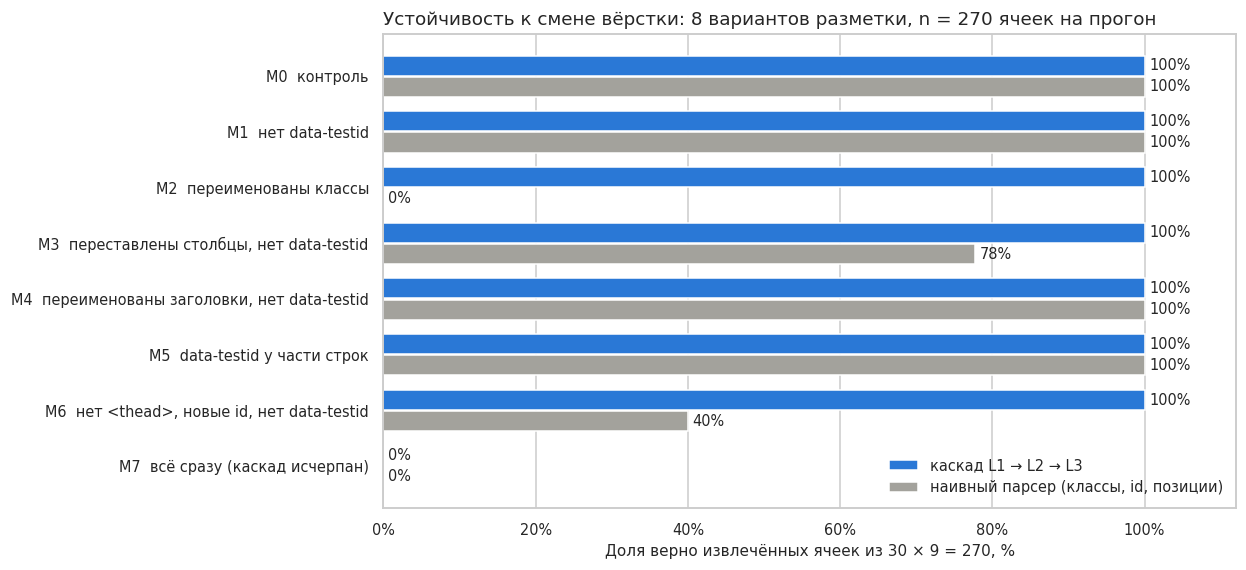

In [11]:
#@title Задание со звёздочкой, направление D: устойчивость к смене вёрстки { display-mode: "form" }
from collections import Counter
from contextlib import redirect_stdout

# ---------------------------------------------------------------- 1. Каскад селекторов
# Уровни по убыванию надёжности: L1 data-testid → L2 семантический XPath (смысл разметки: шапка
# таблицы, id, связь «заголовок — столбец») → L3 текстовый поиск (видимый текст без учёта регистра).
UP = "АБВГДЕЁЖЗИЙКЛМНОПРСТУФХЦЧШЩЪЫЬЭЮЯABCDEFGHIJKLMNOPQRSTUVWXYZ"
LOW = "абвгдеёжзийклмнопрстуфхцчшщъыьэюяabcdefghijklmnopqrstuvwxyz"

def has_text(words):
    """XPath-условие: видимый текст узла содержит одно из слов (регистр не важен)."""
    low = f"translate(normalize-space(.), '{UP}', '{LOW}')"
    return " or ".join(f"contains({low}, '{w}')" for w in words)

ROW_CASCADE = [
    ("L1 data-testid", "//tr[@data-testid='asset-row']"),
    ("L2 семантический XPath", "//table[thead/tr/th]/tbody/tr[td]"),
    ("L3 текстовый поиск", f"//table[.//th[{has_text(['тикер', 'ticker'])}]]//tr[td]"),
]
MORE_CASCADE = [
    ("L1 data-testid", "//button[@data-testid='load-more']"),
    ("L2 семантический XPath", "//button[@id='more' or @name='more' or @aria-label='Показать ещё']"),
    ("L3 текстовый поиск", f"//button[{has_text(['показать ещ', 'загрузить ещ', 'show more', 'load more'])}]"),
]
COOKIE_CASCADE = [
    ("L1 data-testid", "//button[@data-testid='cookie-accept']"),
    ("L2 семантический XPath", "//button[@id='accept' or @name='accept' or @aria-label='Принять']"),
    ("L3 текстовый поиск", f"//button[{has_text(['принять', 'accept', 'согласен'])}]"),
]
HEADER_WORDS = {"rank": ["#", "№", "rank"], "ticker": ["тикер", "ticker"], "name": ["назв", "наимен", "name"],
                "sector": ["сектор", "отрасл", "sector"], "price": ["цен", "price"],
                "change": ["24", "измен", "change"], "volume": ["объём", "объем", "оборот", "volume"],
                "mcap": ["капитал", "cap"], "listed": ["листинг", "дата", "listed"]}

def cell_cascade(field):
    """Ячейка относительно строки. L2/L3 берут номер столбца под заголовком (оси ancestor и
    preceding-sibling) и срабатывают, только если в строке полный набор ячеек — иначе позиции съедут."""
    full_row = "count(../td) = count(ancestor::table[1]//th)"
    exact = f"ancestor::table[1]//th[normalize-space()='{FIELD_HEADERS[field]}']"
    fuzzy = f"(ancestor::table[1]//th[{has_text(HEADER_WORDS[field])}])[1]"
    return [("L1 data-testid", f"./td[@data-testid='{field}']"),
            ("L2 семантический XPath",
             f"./td[{exact}][{full_row}][position() = count({exact}/preceding-sibling::th) + 1]"),
            ("L3 текстовый поиск",
             f"./td[{fuzzy}][{full_row}][position() = count({fuzzy}/preceding-sibling::th) + 1]")]

CELL_CASCADE = {f: cell_cascade(f) for f in CFG["fields"]}

def first_level(node, cascade):
    """Первый уровень каскада, который нашёл узлы: (узлы, уровень)."""
    for level, xp in cascade:
        found = node.xpath(xp)
        if found:
            return found, level
    return [], None

def pick_rows(counts):
    """Строки: берём уровень с наибольшим числом совпадений, при равенстве — более надёжный.
    Так частично пропавший data-testid не обрежет выборку."""
    best = max(n for _, _, n in counts)
    return next((lvl, xp) for lvl, xp, n in counts if n == best) if best else (None, None)

# ---------------------------------------------------------------- 2. Сбор с каскадом
async def dismiss_cascade(page, per_try_ms=1500):
    union = page.locator("xpath=" + " | ".join(xp for _, xp in COOKIE_CASCADE))
    try:
        await union.first.wait_for(state="visible", timeout=per_try_ms)
    except PWTimeout:
        return "не было"
    for level, xp in COOKIE_CASCADE:
        btn = page.locator(f"xpath={xp}").first
        if await btn.is_visible():
            await btn.click(timeout=per_try_ms)
            await btn.wait_for(state="hidden", timeout=per_try_ms)
            return level
    return "не закрыт"

async def collect_resilient(url, timeout_ms=10_000):
    """Тот же сценарий, что в шагах 3–5, но каждый селектор разрешается каскадом во время работы.
    Возвращает (html, уровни по элементам, журнал деградаций)."""
    levels, log, html = {}, [], ""
    async with async_playwright() as pw:
        browser, context = await new_context(pw, HEADLESS)
        page = await context.new_page()
        try:
            await page.goto(url, wait_until="domcontentloaded")
            levels["баннер"] = await dismiss_cascade(page)
            union = " | ".join(xp for _, xp in ROW_CASCADE)
            await page.wait_for_function(COUNT_JS, arg=[union, 1], timeout=timeout_ms)  # сработал хоть один уровень
            counts = [(lvl, xp, await page.locator(f"xpath={xp}").count()) for lvl, xp in ROW_CASCADE]
            levels["строки"], row_xp = pick_rows(counts)
            if counts[0][2] and levels["строки"] != ROW_CASCADE[0][0]:
                log.append(f"data-testid есть только у {counts[0][2]} из {max(n for *_, n in counts)} строк")
            more_level = None
            for lvl, xp in MORE_CASCADE:
                if await page.locator(f"xpath={xp}").count():
                    more_level = lvl
                    break
            levels["кнопка"] = more_level or "не найдена"
            if more_level:
                with redirect_stdout(io.StringIO()):           # построчный журнал догрузки не нужен
                    await load_all(page, row_xp, dict(MORE_CASCADE)[more_level], per_click_ms=5000)
        except PWError as e:
            log.append(f"каскад исчерпан: {str(e).splitlines()[0]}")
        finally:
            try:
                html = await page.content()
            except PWError:
                pass
            await browser.close()
    return html, levels, log

def parse_cascade(html):
    """lxml-разбор с каскадом: строки (максимум совпадений) и каждая ячейка (первый сработавший уровень)."""
    if not html:
        return [], None, Counter()
    tree = lxml_html.fromstring(html)
    row_level, row_xp = pick_rows([(lvl, xp, len(tree.xpath(xp))) for lvl, xp in ROW_CASCADE])
    recs, cell_levels = [], Counter()
    for row in tree.xpath(row_xp) if row_xp else []:
        rec = {}
        for f in CFG["fields"]:
            cells, level = first_level(row, CELL_CASCADE[f])
            rec[f] = cells[0].text_content().strip() if cells else None
            cell_levels[(level or "не найдено").split()[0]] += 1
        recs.append(rec)
    return recs, row_level, cell_levels

# ---------------------------------------------------------------- 3. Наивный парсер для сравнения
# Селекторы, «скопированные из DevTools»: классы, id и позиции столбцов.
NAIVE = {"row": "//tr[td[@class='t']]", "more": "//button[@id='more']", "cookie": "//button[@id='accept']"}
NAIVE_CELLS = {"rank": "./td[@class='t'][1]", "ticker": "./td[@class='t'][2]", "name": "./td[@class='n']",
               "sector": "./td[@class='s']", "price": "./td[5]",
               "change": "./td[contains(@class, 'up') or contains(@class, 'down')]",
               "volume": "./td[7]", "mcap": "./td[8]", "listed": "./td[9]"}

async def collect_naive(url):
    html = ""
    async with async_playwright() as pw:
        browser, context = await new_context(pw, HEADLESS)
        context.set_default_timeout(5000)
        page = await context.new_page()
        try:
            await page.goto(url, wait_until="domcontentloaded")
            try:
                await page.locator(f"xpath={NAIVE['cookie']}").click(timeout=1500)
            except PWError:
                pass
            await wait_for_rows(page, NAIVE["row"], 1, timeout=4000)
            with redirect_stdout(io.StringIO()):
                await load_all(page, NAIVE["row"], NAIVE["more"], per_click_ms=4000)
        except PWError:
            pass
        finally:
            try:
                html = await page.content()
            except PWError:
                pass
            await browser.close()
    if not html:
        return []
    rows = lxml_html.fromstring(html).xpath(NAIVE["row"])
    return [{f: (c[0].text_content().strip() if (c := row.xpath(xp)) else None) for f, xp in NAIVE_CELLS.items()}
            for row in rows]

def accuracy(recs):
    """Доля из 30 × 9 ячеек, совпавших с эталоном основного прогона (исходная вёрстка)."""
    hits = sum(i < len(recs) and recs[i].get(f) == records[i][f] for i in range(len(records)) for f in CFG["fields"])
    return hits / (len(records) * len(CFG["fields"]))

# ---------------------------------------------------------------- 4. Поломки вёрстки
def sub(s, old, new, regex=False):
    out = re.sub(old, new, s, flags=re.S) if regex else s.replace(old, new)
    assert out != s, f"замена не применилась: {old[:40]}"
    return out

def drop_testid(s):
    return sub(s, r'\s*data-testid="[^"]*"', "", regex=True)

def rename_classes(s):
    for old, new in [('class="t"', 'class="css-1x7ab3e"'), ('class="n"', 'class="css-4mz0qa"'),
                     ('class="s"', 'class="css-7hb2ke"'), ('"up" : "down"', '"css-u8f1" : "css-d2k9"'),
                     ("td.t,td.n,td.s", "td.css-1x7ab3e,td.css-4mz0qa,td.css-7hb2ke"),
                     (".up{color:#1a7f4b}.down{color:#b3261e}", ".css-u8f1{color:#1a7f4b}.css-d2k9{color:#b3261e}")]:
        s = sub(s, old, new)
    return s

def rename_ids(s):
    for old, new in [('"accept"', '"x-acc-91"'), ('"more"', '"x-more-5c"'), ("#more{", "#x-more-5c{"),
                     ('"cookie"', '"x-ck-3d"'), ("#cookie{", "#x-ck-3d{"), ("#cookie button{", "#x-ck-3d button{")]:
        s = sub(s, old, new)
    return s

def swap_volume_mcap(s):
    s = sub(s, "<th>Объём</th><th>Капитализация</th>", "<th>Капитализация</th><th>Объём</th>")
    return sub(s, r'(<td data-testid="volume">\$\{d\.volume\}</td>)(\s*)(<td data-testid="mcap">\$\{d\.mcap\}</td>)',
               r"\3\2\1", regex=True)

RENAMED_HEADERS = {"#": "№", "Тикер": "Код (тикер)", "Название": "Наименование", "Сектор": "Отрасль",
                   "Цена": "Цена, ₽", "24ч": "Изм., 24 ч", "Объём": "Оборот",
                   "Капитализация": "Рыночная капитализация", "Листинг": "Дата листинга"}

def rename_headers(s):
    for old, new in RENAMED_HEADERS.items():
        s = sub(s, f"<th>{old}</th>", f"<th>{new}</th>")
    return s

def drop_thead(s):
    return sub(sub(s, "<thead><tr>", "<tr>"), "</tr></thead>", "</tr>")

def partial_testid(s):
    return sub(s, '<tr data-testid="asset-row"', "<tr ${d.rank % 2 ? 'data-testid=\"asset-row\"' : ''}")

def drop_headers(s):
    return sub(s, r"<thead>.*?</thead>", "", regex=True)

MUTATIONS = [   # (код, что сломано, функция, ожидаемое число строк каскада)
    ("M0", "контроль: исходная вёрстка", lambda s: s, 30),
    ("M1", "удалён атрибут data-testid", drop_testid, 30),
    ("M2", "переименованы классы (css-хэши)", rename_classes, 30),
    ("M3", "переставлены столбцы «Объём» и «Капитализация» + нет data-testid",
     lambda s: drop_testid(swap_volume_mcap(s)), 30),
    ("M4", "переименованы заголовки таблицы + нет data-testid", lambda s: drop_testid(rename_headers(s)), 30),
    ("M5", "data-testid пропал у части строк (чётные rank)", partial_testid, 30),
    ("M6", "нет <thead>, переименованы id кнопок + нет data-testid",
     lambda s: drop_testid(rename_ids(drop_thead(s))), 30),
    ("M7", "всё сразу: нет data-testid и шапки, новые id и классы",
     lambda s: rename_classes(rename_ids(drop_testid(drop_headers(s)))), 0),
]

# ---------------------------------------------------------------- 5. Прогон тестов
STAR_DIR = WORK_DIR / "star_d"
STAR_DIR.mkdir(exist_ok=True)
star_rows, t_star = [], time.perf_counter()
for code, title, mutate, expected_rows in MUTATIONS:
    name = f"stand_{code}.html"
    (STAR_DIR / name).write_text(mutate(STAND_HTML), encoding="utf-8")
    url = f"http://127.0.0.1:{STAND_PORT}/{STAR_DIR.name}/{name}?variant={VARIANT}&profile={CFG['profile']}&delay=1200"
    try:
        page_html, levels, log = await collect_resilient(url, timeout_ms=4000 if expected_rows == 0 else 10_000)
        recs, row_level_lxml, cell_levels = parse_cascade(page_html)
        crashed = False
    except Exception as e:                       # тест фиксирует падение, а не скрывает его
        recs, levels, log, cell_levels, crashed = [], {}, [f"исключение {type(e).__name__}: {e}"], Counter(), True
    naive = await collect_naive(url)
    acc, acc_naive = accuracy(recs), accuracy(naive)
    if expected_rows:
        ok = len(recs) == expected_rows and acc == 1.0 and not crashed
    else:                                         # каскад исчерпан: ждём явный отказ без падения и без мусора
        ok = len(recs) == 0 and not crashed and any("исчерпан" in m for m in log)
    if levels.get("строки") and levels["строки"] != ROW_CASCADE[0][0]:
        log.insert(0, f"строки найдены уровнем «{levels['строки']}» — обновите основной селектор")
    if set(cell_levels) - {"L1"}:
        log.insert(1, "ячейки найдены запасными уровнями: " +
                   ", ".join(f"{k}×{v}" for k, v in sorted(cell_levels.items()) if k != "L1"))
    star_rows.append({"код": code, "что сломано": title, "строк": len(recs),
                      "баннер": str(levels.get("баннер", "—")).split()[0],
                      "строки": str(levels.get("строки") or "—").split()[0],
                      "кнопка": str(levels.get("кнопка", "—")).split()[0],
                      "ячейки": ", ".join(f"{k}×{v}" for k, v in sorted(cell_levels.items())) or "—",
                      "точность каскада": acc, "точность наивного": acc_naive, "итог": "✅" if ok else "❌"})
    print(f"{code} {title}: строк {len(recs)}, точность {acc:.0%} (наивный парсер {acc_naive:.0%}) {'✅' if ok else '❌'}")
    for msg in log:
        print(f"   ⚠ {msg}")

star_df = pd.DataFrame(star_rows)
print(f"\nТестов пройдено: {(star_df['итог'] == '✅').sum()} из {len(star_df)} за {time.perf_counter() - t_star:.0f} с. "
      f"Копии стенда: {STAR_DIR}")
display(star_df.assign(**{c: star_df[c].map("{:.0%}".format) for c in ["точность каскада", "точность наивного"]}))

# ---------------------------------------------------------------- 6. График: точность каскада против наивного парсера
s5 = star_df.iloc[::-1]
y = np.arange(len(s5))
fig, ax = plt.subplots(figsize=(10, 5.6))
b1 = ax.barh(y + 0.19, s5["точность каскада"], height=0.36, color=ACCENT, label="каскад L1 → L2 → L3")
b2 = ax.barh(y - 0.19, s5["точность наивного"], height=0.36, color=NEUTRAL, label="наивный парсер (классы, id, позиции)")
for bars in (b1, b2):
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in bars.datavalues], padding=3, fontsize=9.5)
SHORT = {"M0": "контроль", "M1": "нет data-testid", "M2": "переименованы классы",
         "M3": "переставлены столбцы, нет data-testid", "M4": "переименованы заголовки, нет data-testid",
         "M5": "data-testid у части строк", "M6": "нет <thead>, новые id, нет data-testid",
         "M7": "всё сразу (каскад исчерпан)"}
ax.set_yticks(y, [f"{c}  {SHORT[c]}" for c in s5["код"]])
ax.set_xlim(0, 1.12)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel("Доля верно извлечённых ячеек из 30 × 9 = 270, %")
ax.set_title(f"Устойчивость к смене вёрстки: {len(star_df)} вариантов разметки, n = 270 ячеек на прогон", loc="left")
ax.legend(loc="lower right", frameon=False)
ax.grid(axis="y", visible=False)
fig.savefig(STAR_DIR / "star_d_accuracy.png", dpi=150, bbox_inches="tight")
plt.show()

**Интерпретация результатов направления D.**

| Поломка | Каскад | Сработавшие уровни | Наивный парсер |
|---|---:|---|---:|
| M0 контроль | 100 % | всё L1 | 100 % |
| M1 нет `data-testid` | 100 % | всё L2 | 100 % |
| M2 переименованы классы | 100 % | всё L1 | **0 %**: строки не найдены, ожидание завершилось таймаутом |
| M3 переставлены столбцы, нет `data-testid` | 100 % | L2: позиции пересчитаны по заголовкам | **78 % без единой ошибки**: «Объём» и «Капитализация» молча перепутаны |
| M4 переименованы заголовки, нет `data-testid` | 100 % | строки L2, ячейки L3: синонимы заголовков | 100 % |
| M5 `data-testid` у части строк | 100 % | строки L2 (по максимуму совпадений), ячейки L1 | 100 % |
| M6 нет `<thead>`, новые id, нет `data-testid` | 100 % | баннер, строки и кнопка — L3, ячейки — L2 | **40 %**: кнопка не найдена, собраны 12 строк из 30 |
| M7 всё сразу | 0 % — явный отказ «каскад исчерпан» | баннер L3, дальше ни один уровень | 0 % |

Выводы:

1. **Каскад выдержал все 6 поломок** (M1–M6) со 100 % точностью на 270 ячейках. Каждый уровень сработал на деле: L2 спасал при пропаже `data-testid`, L3 — при смене структуры и текста заголовков. Каждое такое переключение попадает в журнал, это готовый сигнал для мониторинга: «вёрстка изменилась, основной селектор пора обновить».
2. **Самая опасная поломка — тихая.** На M3 наивный парсер не упал и вернул правдоподобные числа, но 60 из 270 значений (2 столбца × 30 строк) оказались в чужих колонках. Без сверки с эталоном этого не заметить. Каскад привязан к смыслу (`data-testid`, текст заголовка), а не к номеру столбца, поэтому такая перестановка ему не страшна.
3. **Классы и id — плохой якорь.** Переименование классов (M2), типичное для CSS-in-JS после релиза, обнулило наивный парсер. Смена id (M6) лишила его кнопки догрузки, и выборка неполная. Это подтверждает порядок надёжности из теоретического блока 3: `data-testid` → семантика → текст → позиция.
4. **Отказ лучше мусора.** Когда исчезли все якоря (M7), каскад не стал угадывать: он остановился с понятной причиной и сохранил HTML для разбора. Позиционные уровни включаются только для строк с полным набором ячеек, а для строк выбирается уровень с максимумом совпадений, поэтому частичная деградация (M5) не обрезала выборку.

**Ограничения.** Уровень L3 зависит от языка интерфейса и формулировок: словарь синонимов придётся расширять для новых площадок. Каскад вычисляет до трёх XPath-выражений на элемент вместо одного, но на фоне работы браузера это копейки. Тесты моделируют типовые изменения вёрстки и не заменяют мониторинг на реальной площадке.